## **Trabajo Práctico Final: Telco Churn**
____
__Universidad Tecnológica Nacional, Buenos Aires__\
__Ingeniería Industrial__\
__Ciencia de Datos - Curso I5571__
____
**Notebook 3 de 3: Machine learning**

**Grupo 6**

| Legajo | Integrante |
|---|---|
| 1764111 | Guillermo Inostroza |
| 1772752 | Erik Yuji Tanaka |
| 1593973 | Iñaki Hegoburu |
| 2042873 | Julián Longo |

# 1. Objetivo

La consigna pide "un pipeline de machine learning para predecir la variable Churn" y, además, aplicar un método de reducción de la dimensionalidad y volver a predecir. En este notebook construimos el pipeline paso a paso, elegimos el modelo y el umbral de decisión con la matriz de costos que fijó el EDA, repetimos la predicción con PCA y evaluamos todo una sola vez en test. Al final interpretamos el modelo y traducimos el resultado a clientes y costos.

Trabajamos sobre `data/telco_manipulado.csv`, que genera `clusterai_guillermo_inostroza_manipulacion.ipynb` a partir de la partición de `clusterai_guillermo_inostroza_eda.ipynb`. Citamos las decisiones del EDA por su número ("decisión 18 del EDA") y numeramos las de este notebook de ML1 a ML14. El informe `clusterai_reporte_inostroza.pdf` resume los resultados.

Cada bloque de código va precedido de un texto que dice qué hace, por qué lo hacemos y qué esperamos ver. Después de las salidas que lo requieren interpretamos el resultado, y las decisiones quedan en recuadros con su justificación.

## Índice

| Sección | Qué hacemos | Por qué |
|---|---|---|
| 2. Configuración y datos | Fijamos semilla, rutas, columnas, folds y costos; cargamos los datos y apartamos el test | Ninguna decisión puede depender del test |
| 3. Protocolo de evaluación | Fijamos la validación cruzada, la métrica, las reglas de adopción y la matriz de costos | Las reglas se eligen antes de ver resultados |
| 4. Líneas de base | Evaluamos un clasificador nulo y una logística con el preprocesamiento mínimo | Sin una referencia, un AUC no dice si es mucho o poco |
| 5. Preprocesamiento | Probamos de a una las decisiones abiertas del EDA, con comparaciones pareadas | Cada paso del pipeline tiene que justificarse con evidencia |
| 6. Modelos | Comparamos seis familias con `GridSearchCV` y elegimos por la regla de un error estándar | Las diferencias son chicas y, entre empatados, conviene el más simple |
| 7. Umbral | Elegimos el umbral con la matriz de costos y medimos su sensibilidad | El 0,5 por defecto no responde a los costos del problema |
| 8. PCA | Reducimos la dimensión y volvemos a predecir con logística y Random Forest | Lo pide la consigna y muestra la estructura de los datos |
| 9. Test | Medimos una sola vez tres modelos fijados de antemano, con intervalos bootstrap | Es la estimación del desempeño con clientes nuevos |
| 10. Interpretación y negocio | Odds ratios, perfiles, importancia por permutación y costos | El modelo tiene que servir para decidir acciones |
| 11. Conclusiones | Conclusiones, limitaciones y registro de decisiones | Reúne qué decidimos y con qué evidencia |
| 12. Referencias | Bibliografía citada | Respaldo de las citas del texto |

# 2. Configuración y datos

En esta sección dejamos fijo todo lo que el resto del notebook da por sentado: las librerías, la semilla, las rutas, el rol de cada columna, los folds de validación y los costos. Después cargamos los datos y separamos train de test. La configuración repite la del EDA y todo el modelado usa scikit-learn (Pedregosa et al., 2011).

## 2.1 Librerías

Los módulos que importamos anticipan el recorrido del notebook:

- `ColumnTransformer`, `Pipeline`, `SimpleImputer`, `KNNImputer`, `OneHotEncoder`, `StandardScaler` y `FunctionTransformer` arman el preprocesamiento.
- `StratifiedKFold`, `cross_validate`, `cross_val_predict` y `GridSearchCV` hacen la validación cruzada y la búsqueda de hiperparámetros.
- Los modelos son `DummyClassifier`, `LogisticRegression`, `KNeighborsClassifier`, `DecisionTreeClassifier`, `RandomForestClassifier`, `HistGradientBoostingClassifier`, `MLPClassifier` y `VotingClassifier`.
- `PCA` reduce la dimensión; `roc_auc_score`, `roc_curve` y `confusion_matrix` miden, y `permutation_importance` ayuda a interpretar.

Al final imprimimos las versiones. Un cambio de versión de scikit-learn puede mover algún resultado en la cuarta cifra, y con este dato se puede reproducir el entorno.

In [1]:
import os                                           # rutas relativas
import time                                         # tiempos de cada búsqueda
import warnings                                     # silenciar un aviso puntual de joblib
import platform                                     # versión de Python

import numpy as np                                  # cálculo numérico
import pandas as pd                                 # tablas de datos
import matplotlib                                   # gráficos (base)
import matplotlib.pyplot as plt                     # interfaz para armar figuras
import seaborn as sns                               # gráficos estadísticos
import sklearn                                      # scikit-learn (para ver la versión)

from sklearn.compose import ColumnTransformer       # un preprocesamiento distinto por grupo de columnas
from sklearn.pipeline import Pipeline               # encadena preprocesamiento y modelo
from sklearn.impute import SimpleImputer, KNNImputer   # imputadores
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer   # codificar, escalar, transformar
from sklearn.decomposition import PCA               # análisis de componentes principales
from sklearn.model_selection import (StratifiedKFold, cross_validate,   # validación cruzada (sigue abajo)
                                     cross_val_predict, GridSearchCV)   # validación cruzada y búsqueda de hiperparámetros
from sklearn.dummy import DummyClassifier           # modelo que no aprende (línea de base)
from sklearn.linear_model import LogisticRegression # regresión logística
from sklearn.neighbors import KNeighborsClassifier  # K vecinos más cercanos
from sklearn.neural_network import MLPClassifier    # perceptrón multicapa
from sklearn.tree import DecisionTreeClassifier, plot_tree   # árbol de decisión y su dibujo
from sklearn.ensemble import (RandomForestClassifier, HistGradientBoostingClassifier,   # ensambles de árboles (sigue abajo)
                              VotingClassifier)     # ensambles de árboles y votación
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix   # métricas
from sklearn.inspection import permutation_importance   # importancia por permutación

warnings.filterwarnings('ignore', message='.*sklearn.utils.parallel.delayed.*')   # aviso interno de joblib al paralelizar en dos niveles; no afecta resultados

print('Python      ', platform.python_version())   # versión de Python
for lib in [pd, np, matplotlib, sns, sklearn]:      # recorro las librerías
    print(f'{lib.__name__:12s}', lib.__version__)   # nombre y versión

Python       3.14.6
pandas       3.0.3
numpy        2.4.6
matplotlib   3.11.0
seaborn      0.13.2
sklearn      1.9.0


## 2.2 Semilla y rutas

Fijamos la semilla en 42, la misma del EDA y del notebook de manipulación. Varios pasos dependen del azar: el reparto de clientes en los folds, los árboles de Random Forest y del boosting, los pesos iniciales de la red neuronal y el bootstrap de la sección 9. Con la semilla fija, cada corrida da exactamente los mismos números, y una diferencia entre dos modelos no puede deberse a un sorteo distinto.

Las rutas son relativas a la carpeta del trabajo. Los datos salen de `data/telco_manipulado.csv` y las figuras se guardan en `figuras/`, que creamos si no existe.

In [2]:
SEED = 42                                                   # misma semilla en todo el trabajo
RUTA_DATOS = os.path.join('data', 'telco_manipulado.csv')   # salida del notebook de manipulación
CARPETA_FIGURAS = 'figuras'                                 # carpeta de figuras del informe
os.makedirs(CARPETA_FIGURAS, exist_ok=True)                 # la creo si no existe

## 2.3 Rol de cada columna

`Churn` es la variable objetivo: indica si el cliente se dio de baja ("Yes") o no ("No"), que es lo que la consigna pide predecir. `customerID` identifica a cada cliente con un código arbitrario y no describe nada de él. Si entrara al modelo, cada código sería una categoría única y el modelo podría memorizar clientes de train en lugar de aprender patrones que se repitan en clientes nuevos. Por eso solo la usamos para controlar que no haya filas repetidas. La columna `conjunto` marca la partición y tampoco es predictora.

Separamos además dos grupos que el preprocesamiento trata de forma especial. Las tres numéricas reciben imputación por mediana y escalado. Los seis servicios adicionales que requieren internet intervienen en la recodificación de la decisión 11 y en el conteo de la decisión 15.

In [3]:
TARGET = 'Churn'                                            # variable objetivo
COLS_NUM = ['tenure', 'MonthlyCharges', 'TotalCharges']     # numéricas
ADICIONALES = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',   # seguridad, respaldo y protección
               'TechSupport', 'StreamingTV', 'StreamingMovies']   # servicios que requieren internet

## 2.4 Folds de validación

Usamos una única partición de train en 5 folds estratificados (decisión 14 del EDA). Estratificar quiere decir que cada fold conserva la proporción de bajas de train, cerca del 26,5%; sin eso, un fold con pocas bajas daría un AUC más ruidoso. Con `shuffle=True` y la semilla, los clientes se reparten al azar, pero siempre de la misma manera.

Definimos el objeto una sola vez y lo pasamos a todas las funciones. Así todos los modelos se miden sobre los mismos clientes en cada fold, lo que permite la comparación pareada que explicamos en la sección 3.

In [4]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)   # los mismos 5 folds para todo el notebook

## 2.5 Costos

Los dos supuestos de costo vienen de la decisión 18 del EDA. Perder un cliente cuesta 897, que son 12 meses del cargo mensual medio de los clientes que se van, y la oferta de retención cuesta 120. Los fijamos antes de entrenar para que el umbral de la sección 7 no termine acomodado a los resultados. Su cociente, 120 / 897 ≈ 0,134, será el umbral teórico.

In [5]:
PERDIDA = 897                                               # decisión 18: 12 meses del cargo medio de los que se van
OFERTA = 120                                                # decisión 18: costo de la oferta de retención

## 2.6 Estilo y funciones auxiliares

Repetimos la paleta del EDA (azul para los clientes que se quedan, naranja para los que se van) y mostramos las tablas con cuatro decimales, porque muchos AUC difieren en milésimas. Definimos también dos funciones auxiliares. `guardar_figura` guarda cada gráfico en alta resolución para el informe. `verificar` detiene el notebook con un mensaje claro cuando un control falla, para que nunca siga con datos equivocados.

In [6]:
AZUL_UTN, AZUL_OSCURO, CELESTE, NARANJA, GRIS = '#1C6094', '#0B2E4F', '#7FB3D5', '#EE8D35', '#6B7B8C'   # paleta del EDA
COLORES_CHURN = {0: AZUL_UTN, 1: NARANJA}                   # azul = se queda, naranja = se va
sns.set_theme(style='whitegrid', context='notebook',        # fondo blanco con grilla y tamaño de notebook
              palette=[AZUL_UTN, NARANJA, CELESTE, AZUL_OSCURO, GRIS])   # estilo de los gráficos
plt.rcParams.update({'axes.titleweight': 'bold', 'axes.titlecolor': AZUL_OSCURO,   # títulos en negrita y azul oscuro
                     'axes.edgecolor': '#B8C4CF', 'grid.color': '#E3E9EF'})   # títulos y grilla
pd.set_option('display.max_columns', 40)                    # muestro todas las columnas
pd.set_option('display.float_format', '{:.4f}'.format)      # 4 decimales (los AUC difieren en milésimas)


def guardar_figura(nombre):   # guarda la figura actual en figuras/
    # PNG en alta resolución, con prefijo ml_ para distinguirla de las del EDA
    plt.savefig(os.path.join(CARPETA_FIGURAS, 'ml_' + nombre + '.png'), dpi=150, bbox_inches='tight')   # PNG a 150 dpi, sin márgenes sobrantes


def verificar(condicion, mensaje):   # control con mensaje claro
    # si la condición no se cumple, detiene el notebook diciendo qué falló
    if not condicion:                                       # el control falló
        raise ValueError('Falló el control: ' + mensaje)    # corto acá
    print('OK -', mensaje)                                  # el control pasó

## 2.7 Resumen de la configuración

Imprimimos la configuración en un solo lugar para poder revisarla de un vistazo antes de seguir.

In [7]:
print('Semilla:', SEED)                                     # semilla de todo el notebook
print('Datos:', RUTA_DATOS, '| figuras en:', CARPETA_FIGURAS)   # rutas
print('Objetivo:', TARGET, '| fuera del modelo: customerID (identificador) y conjunto (partición)')   # rol de las columnas
print('Numéricas:', COLS_NUM)                               # reciben mediana y escalado
print('Adicionales que requieren internet:', ADICIONALES)   # recodificación y conteo
print(f'Validación: StratifiedKFold, {CV.get_n_splits()} folds, shuffle={CV.shuffle}, random_state={CV.random_state}')   # folds comunes
print(f'Costos: pérdida {PERDIDA}, oferta {OFERTA}, cociente {OFERTA / PERDIDA:.3f}')   # decisión 18 del EDA

Semilla: 42
Datos: data/telco_manipulado.csv | figuras en: figuras
Objetivo: Churn | fuera del modelo: customerID (identificador) y conjunto (partición)
Numéricas: ['tenure', 'MonthlyCharges', 'TotalCharges']
Adicionales que requieren internet: ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
Validación: StratifiedKFold, 5 folds, shuffle=True, random_state=42
Costos: pérdida 897, oferta 120, cociente 0.134


## 2.8 Carga de los datos

Leemos el archivo que deja el notebook de manipulación y, antes de usarlo, controlamos tres cosas: que haya un cliente por fila, que la partición sea la de la decisión 4 del EDA y que `Churn` no tenga faltantes. Si alguna falla, el notebook se detiene. Esperamos 7.043 filas y 22 columnas: las 19 variables, el objetivo, `customerID` y `conjunto`.

In [8]:
verificar(os.path.exists(RUTA_DATOS), f'existe {RUTA_DATOS} (correr antes el notebook de manipulación)')   # ¿está el archivo?
datos = pd.read_csv(RUTA_DATOS)                             # leo los datos manipulados
print('Shape:', datos.shape)                                # filas y columnas
verificar(datos['customerID'].is_unique, 'un cliente por fila')   # sin repetidos
verificar(datos['conjunto'].value_counts().to_dict() == {'train': 5634, 'test': 1409},   # clientes por conjunto contra lo esperado
          'partición de la decisión 4: 5.634 en train y 1.409 en test')   # misma partición del EDA
verificar(datos[TARGET].notna().all(), 'Churn completo')    # el objetivo no tiene faltantes

OK - existe data/telco_manipulado.csv (correr antes el notebook de manipulación)
Shape: (7043, 22)
OK - un cliente por fila
OK - partición de la decisión 4: 5.634 en train y 1.409 en test
OK - Churn completo


Separamos train y test según la columna `conjunto`. Las variables (`X`) son todas las columnas salvo `customerID`, `conjunto` y `Churn`: quedan 19, de las cuales 3 son numéricas y 16 categóricas. El objetivo pasa a 1 si el cliente se va y a 0 si se queda, la codificación que esperan las métricas de scikit-learn. De test solo imprimimos el tamaño, porque su tasa de churn no se mira hasta la sección 9.

In [9]:
train = datos[datos['conjunto'] == 'train'].reset_index(drop=True)   # clientes de train
test = datos[datos['conjunto'] == 'test'].reset_index(drop=True)     # clientes de test (no se miran hasta la sección 9)
COLS_X = [c for c in datos.columns if c not in ['customerID', 'conjunto', TARGET]]   # las 19 variables
COLS_CAT = [c for c in COLS_X if c not in COLS_NUM]         # las 16 categóricas
print(f'Variables predictoras: {len(COLS_X)} ({len(COLS_NUM)} numéricas y {len(COLS_CAT)} categóricas)')   # las que entran al preprocesamiento

X_train = train[COLS_X]                                     # variables de train
y_train = (train[TARGET] == 'Yes').astype(int).to_numpy()  # 1 = se va, 0 = se queda
X_test = test[COLS_X]                                       # variables de test
y_test = (test[TARGET] == 'Yes').astype(int).to_numpy()    # objetivo de test

print(f'Train: {X_train.shape} | churn {y_train.mean():.1%}')   # tamaño y tasa en train
print(f'Test:  {X_test.shape} | la tasa de test no se mira hasta la sección 9')   # solo el tamaño
print('Faltantes en train:', int(X_train.isna().sum().sum()), 'celdas')   # los imputa el pipeline

Variables predictoras: 19 (3 numéricas y 16 categóricas)
Train: (5634, 19) | churn 26.5%
Test:  (1409, 19) | la tasa de test no se mira hasta la sección 9
Faltantes en train: 8450 celdas


El archivo trae los 7.043 clientes con el formato corregido (decisiones 1 a 3 del EDA), los faltantes deducibles ya completados con las reglas R1 a R9 (decisión 7) y la columna `conjunto` con la partición de la decisión 4. Los 8.450 faltantes que quedan en train llegan como `NaN` y los imputa el pipeline.

> **Decisión ML1:** partir de `data/telco_manipulado.csv`, verificar que conserve la partición del EDA y apartar el test hasta la evaluación final.
>
> **Justificación:** las transformaciones sin estado ya están aplicadas y controladas en el notebook de manipulación; repetirlas acá abriría la posibilidad de que los dos notebooks diverjan. El test queda fuera de toda decisión (preprocesamiento, modelo, hiperparámetros, umbral y cantidad de componentes), porque cualquier elección tomada mirándolo vuelve optimista la métrica final (Géron, 2022, cap. 2; James et al., 2023, cap. 5).

# 3. Protocolo de evaluación

Fijamos las reglas antes de entrenar cualquier modelo, para que ninguna termine acomodada a un resultado.

**Validación.** La `StratifiedKFold` de 5 folds que definimos en la sección 2.4 sirve para todos los experimentos. Como todos los modelos se miden sobre los mismos clientes en cada fold, podemos comparar fold por fold: al restar, se cancela la parte de la variación que se debe a que un fold es más fácil que otro. Esto importa porque las diferencias entre configuraciones son de milésimas y la variación entre folds es de centésimas.

**Métrica.** Usamos ROC-AUC (decisión 13 del EDA), que mide cómo ordena el modelo a los clientes por riesgo sin depender del umbral ni del desbalance (Hanley y McNeil, 1982). El umbral se decide aparte, con costos.

**Regla para el preprocesamiento.** Con el mismo modelo, adoptamos un cambio si la diferencia pareada media supera dos errores estándar y además es de al menos 0,001 de AUC. Si no cumple las dos condiciones lo tratamos como empate y nos quedamos con la opción más simple. Pedimos dos errores estándar porque los folds comparten la mayor parte de train y el error estándar subestima la incertidumbre real (Nadeau y Bengio, 2003). El piso de una milésima descarta diferencias consistentes pero irrelevantes, que aparecen cuando dos variantes son casi el mismo modelo y el error estándar de su diferencia se acerca a cero.

**Regla para los modelos.** Entre los modelos cuyo AUC medio queda dentro de un error estándar del mejor, elegimos el más simple (James et al., 2023, sec. 6.1.3). Acá "simple" incluye que se pueda interpretar y que sus probabilidades sirvan para el umbral por costos.

Usamos a propósito dos reglas distintas. La del preprocesamiento es pareada porque compara dos versiones del mismo modelo que difieren en un solo paso. La de los modelos usa el error estándar del AUC medio, sin parear, porque es la regla estándar de James et al. (2023, sec. 6.1.3) y la fijamos antes de ver resultados. Es más exigente a propósito: un modelo más complejo cuesta interpretabilidad y mantenimiento, así que tiene que superar un margen mayor que un cambio de preprocesamiento.

**Costos (decisión 18 del EDA).** Perder un cliente cuesta 897 (12 meses del cargo medio de los que se van) y la oferta de retención cuesta 120. Si `r` es la parte de la pérdida que la oferta recupera:

| | No se le ofrece | Se le ofrece |
|---|---|---|
| Se queda | 0 | 120 |
| Se va | 897 | 120 + (1 - r) × 897 |

Para un cliente con probabilidad de irse $p$, el costo esperado de cada decisión sale de la tabla:

$$\text{sin oferta: } p \cdot 897 \qquad\qquad \text{con oferta: } 120 + p\,(1 - r) \cdot 897$$

Conviene ofrecer cuando el segundo es menor, es decir, cuando $p\,r \cdot 897 > 120$, o sea $p > \dfrac{120}{r \cdot 897}$. En el escenario base, $r = 1$, la regla queda $p > 120 / 897 \approx 0{,}134$. La deducción vale si las probabilidades están calibradas (Murphy, 2022, sec. 5.1.2.2), y lo controlamos en la sección 7.

> **Decisión ML2:** evaluar todo con la misma `StratifiedKFold(5, shuffle=True, random_state=42)` sobre train y por ROC-AUC. Adoptar cambios de preprocesamiento por diferencia pareada (más de dos errores estándar y al menos 0,001). Elegir el modelo por la regla de un error estándar y el umbral por la matriz de costos.
>
> **Justificación:** con folds comunes, la comparación pareada es mucho más precisa que comparar promedios sueltos, y tratar las opciones de preprocesamiento como hiperparámetros evaluados en los mismos folds evita decidirlas a ojo (VanderPlas, 2016, cap. 5; James et al., 2023, secs. 5.1.3 y 5.1.5). Separar el AUC del umbral deja la discusión de costos en un solo lugar. Fijar las reglas antes de ver resultados impide elegir el criterio que favorece a un modelo.

## 3.1 Funciones de evaluación

Escribimos las reglas anteriores como dos funciones, para aplicarlas siempre igual. `evaluar_cv` entrena un pipeline cinco veces, una por fold, y devuelve los cinco AUC de validación. `comparar` resume esos AUC con su media y su desvío y, si recibe una referencia, calcula la diferencia fold por fold. El error estándar de esa diferencia es su desvío dividido por la raíz de 5. Con él, la función aplica la regla de adopción y devuelve el veredicto ("mejora", "empeora" o "empate").

Cada resultado queda guardado en la lista `experimentos`, de donde salen las tablas posteriores. Esta celda solo define funciones y no imprime nada.

In [10]:
experimentos = []                                           # registro de cada experimento


def evaluar_cv(modelo):   # AUC de validación cruzada
    # entrena el modelo 5 veces (una por fold) y devuelve el AUC de cada fold de validación
    return cross_validate(modelo, X_train, y_train, cv=CV, scoring='roc_auc', n_jobs=-1)['test_score']   # AUC de cada fold de validación


def comparar(nombre, puntajes, referencia=None, nombre_ref=''):   # registra y compara contra una referencia
    # imprime media y desvío del AUC; con referencia, la diferencia pareada, su error estándar y el veredicto
    fila = {'experimento': nombre, 'AUC medio': puntajes.mean(), 'desvío': puntajes.std(ddof=1)}   # resumen del CV
    texto = f'{nombre:48s} AUC {puntajes.mean():.4f} ± {puntajes.std(ddof=1):.4f}'   # línea a imprimir
    if referencia is not None:                              # comparación pareada
        dif = puntajes - referencia                         # diferencia fold por fold
        ee = dif.std(ddof=1) / np.sqrt(len(dif))            # error estándar de la diferencia
        if dif.mean() > 2 * ee and dif.mean() >= 0.001:     # mejora consistente y de al menos una milésima
            veredicto = 'mejora'                            # se adopta
        elif dif.mean() < -2 * ee and dif.mean() <= -0.001: # empeora de forma consistente y relevante
            veredicto = 'empeora'                           # se descarta
        else:                                               # dentro del ruido
            veredicto = 'empate'                            # gana la opción más simple
        fila.update({'contra': nombre_ref, 'diferencia': dif.mean(), 'EE dif.': ee,   # contra quién, diferencia y su EE
                     'folds que gana': int((dif > 0).sum()), 'veredicto': veredicto})   # agrego la comparación
        texto += f' | vs {nombre_ref}: {dif.mean():+.4f} (EE {ee:.4f}, gana {int((dif > 0).sum())}/5) -> {veredicto}'   # comparación en el texto
    experimentos.append(fila)                               # guardo el experimento
    print(texto)                                            # muestro el resultado
    return puntajes                                         # devuelvo los AUC por fold

## 3.2 Costo de una decisión

`costo_total` aplica la matriz de costos a una decisión concreta. Recibe las bajas reales, las probabilidades del modelo y un umbral. A cada cliente con probabilidad igual o mayor al umbral se le ofrece la retención, y la función suma el costo de las cuatro celdas de la matriz. El parámetro `recuperado` es la `r` de la tabla: en el escenario base vale 1 y lo variamos en la sección 7. Al final calculamos el umbral teórico del escenario base; esperamos 0,134.

In [11]:
def costo_total(y, prob, umbral, perdida=PERDIDA, oferta=OFERTA, recuperado=1.0):   # matriz de costos de la decisión 18
    # costo de ofrecer la retención a todos los clientes con probabilidad >= umbral
    ofrece = prob >= umbral                                 # a quién le ofrecemos
    se_va = y == 1                                          # quién se va en realidad
    costo = (ofrece & se_va) * (oferta + (1 - recuperado) * perdida)   # ofrecimos y se iba: oferta + lo no recuperado
    costo = costo + (ofrece & ~se_va) * oferta              # ofrecimos y se quedaba: oferta de más
    costo = costo + (~ofrece & se_va) * perdida             # no ofrecimos y se fue: cliente perdido
    return float(costo.sum())                               # costo total


UMBRAL_TEORICO = OFERTA / PERDIDA                           # umbral óptimo con r = 1
print(f'Umbral teórico: {OFERTA} / {PERDIDA} = {UMBRAL_TEORICO:.3f}')   # muestro el resultado

Umbral teórico: 120 / 897 = 0.134


# 4. Líneas de base

Armamos el preprocesamiento con una función cuyos argumentos son las decisiones abiertas del EDA. Todo lo que aprende de los datos (medianas, modas, categorías del one-hot, medias y desvíos del escalado) queda dentro del `Pipeline`. Así se reajusta en cada fold solo con los clientes de entrenamiento y no hay fuga hacia el fold de validación (Géron, 2022, cap. 2). Las transformaciones sin estado (recodificar, `log1p`, contar adicionales, cortar `tenure` en tramos) entran como `FunctionTransformer`.

## 4.1 Transformaciones sin estado

Una transformación sin estado no aprende nada de los datos: aplica la misma regla a cualquier cliente, sea de train, de validación o de test. Por eso no puede filtrar información entre folds. Definimos cuatro:

- `recodificar_sin_internet` reemplaza "No internet service" por "No" en los seis adicionales (decisión 11). El dato de que el cliente no tiene internet sigue en `InternetService`.
- `contar_adicionales` cuenta cuántos adicionales contrató el cliente (decisión 15).
- `tramos_tenure` corta la antigüedad en los cinco tramos fijos del EDA (decisión 15).
- `log_total` aplica `log1p` a `TotalCharges` dentro de la variante con `KNNImputer`.

Esta celda solo define las funciones.

In [12]:
def recodificar_sin_internet(Z):   # decisión 11 del EDA (sin estado)
    # reemplaza "No internet service" por "No" en los adicionales; la información queda en InternetService_No
    Z = np.asarray(Z, dtype=object)                         # arreglo de objetos (texto y NaN)
    return np.where(Z == 'No internet service', 'No', Z)    # recodifico


def contar_adicionales(Z):   # decisión 15 del EDA: n_adicionales
    # cuenta cuántos de los 6 adicionales tiene el cliente (un faltante cuenta como no contratado)
    Z = np.asarray(Z, dtype=object)                         # arreglo de texto
    return (Z == 'Yes').sum(axis=1).reshape(-1, 1).astype(float)   # una columna con la cantidad


def tramos_tenure(Z):   # decisión 15 del EDA: tramos de antigüedad
    # tramos del EDA: 0-6, 7-12, 13-24, 25-48 y 49-72 meses (cortes fijos, sin estado)
    Z = np.asarray(Z, dtype=float)                          # arreglo numérico
    return np.digitize(Z, [6.5, 12.5, 24.5, 48.5]).astype(str)   # número de tramo como texto


def log_total(Z):   # log1p en TotalCharges para la variante con KNNImputer
    # aplica log1p solo a la tercera columna (TotalCharges)
    Z = np.array(Z, dtype=float)                            # copia numérica
    Z[:, 2] = np.log1p(Z[:, 2])                             # log1p en TotalCharges
    return Z                                                # devuelvo el arreglo

## 4.2 El preprocesador configurable

`armar_preprocesador` arma un `ColumnTransformer`, que aplica un tratamiento distinto a cada grupo de columnas y une los resultados en una sola matriz. Cada argumento corresponde a una decisión que comparamos por validación cruzada. Con los valores por defecto, los bloques son estos:

| Bloque | Columnas | Pasos |
|---|---|---|
| `num` | `tenure`, `MonthlyCharges` | mediana, `StandardScaler` |
| `tc` | `TotalCharges` | mediana, `log1p`, `StandardScaler` |
| `cat` | las categóricas | recodificación, "Desconocido", one-hot |
| `nadic`, `tramos` | opcionales | conteo de adicionales; tramos de `tenure` en one-hot |

Imputamos las numéricas con la mediana porque no la mueve la cola larga de `TotalCharges`. `StandardScaler` resta la media y divide por el desvío aprendidos en el fold de entrenamiento. Lo necesitamos porque la penalización L2 castiga por igual a todos los coeficientes, y eso solo es justo si las variables están en escalas comparables; KNN y PCA también dependen de la escala.

El one-hot convierte cada categoría en una columna 0/1. Los modelos necesitan entradas numéricas, y numerar las categorías como 1, 2, 3 les impondría un orden que no existe. Con `drop='if_binary'`, una variable de dos categorías queda en una sola columna, porque la segunda sería redundante. Con `handle_unknown='ignore'`, una categoría que no apareció en el fold de entrenamiento se codifica con ceros en lugar de dar error. Las columnas que ningún bloque nombra quedan afuera (`remainder='drop'`), y así salen `customerID`, `conjunto` y las excluidas.

`logistica` une el preprocesador con una regresión logística. El modelo estima el logaritmo de las odds de baja como una combinación lineal de las columnas:

$$\log \frac{p}{1 - p} = \beta_0 + \beta_1 x_1 + \dots + \beta_m x_m$$ scikit-learn le aplica por defecto una penalización L2 con `C = 1`; `C` es la inversa de la fuerza de esa penalización. Usamos `max_iter=2000` para que el optimizador llegue a converger. Esta celda solo define funciones.

In [13]:
def armar_preprocesador(imputar_cat='Desconocido', recodificar=True, log1p_total=True, excluir=(),   # preprocesador configurable
                        sin_total=False, n_adicionales=False, tramos=False, knn_numericas=False,   # opciones de la sección 5
                        imputar_num=True):                  # False: deja los NaN de las numéricas para el boosting
    # arma el ColumnTransformer; cada argumento es una decisión que comparamos por validación cruzada
    categoricas = [c for c in COLS_CAT if c not in excluir]  # categóricas que entran
    bloques = []                                            # bloques del ColumnTransformer
    if knn_numericas:                                       # variante: KNNImputer sobre las tres numéricas
        bloques.append(('num', Pipeline([('log', FunctionTransformer(log_total)),   # log1p en TotalCharges (NaN sigue NaN)
                                         ('escalar', StandardScaler()),   # escalo antes: la distancia no debe depender de la unidad
                                         ('imputar', KNNImputer(n_neighbors=10))]), COLS_NUM))   # 10 vecinos más cercanos
    else:                                                   # caso normal: mediana
        numericas = ['tenure', 'MonthlyCharges'] + ([] if (sin_total or log1p_total) else ['TotalCharges'])   # numéricas sin log
        imputador = [('imputar', SimpleImputer(strategy='median'))] if imputar_num else []   # mediana (o nada)
        bloques.append(('num', Pipeline(imputador + [('escalar', StandardScaler())]), numericas))   # StandardScaler deja pasar los NaN
        if log1p_total and not sin_total:                   # TotalCharges con log1p
            bloques.append(('tc', Pipeline(imputador + [   # mediana (o nada), log1p y escala
                                            ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),   # log1p sin estado
                                            ('escalar', StandardScaler())]), ['TotalCharges']))   # bloque de TotalCharges
    pasos_cat = []                                          # pasos para las categóricas
    if recodificar:                                         # decisión 11
        pasos_cat.append(('recodificar', FunctionTransformer(recodificar_sin_internet, feature_names_out='one-to-one')))   # sin estado
    if imputar_cat == 'Desconocido':                        # decisión 8: categoría propia
        pasos_cat.append(('imputar', SimpleImputer(strategy='constant', fill_value='Desconocido')))   # categoría constante
    else:                                                   # decisión 8: la moda
        pasos_cat.append(('imputar', SimpleImputer(strategy='most_frequent')))   # aprende la moda en train
    pasos_cat.append(('onehot', OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False)))   # decisión 11
    bloques.append(('cat', Pipeline(pasos_cat), categoricas))   # bloque categórico
    if n_adicionales:                                       # decisión 15: cantidad de adicionales
        bloques.append(('nadic', Pipeline([('contar', FunctionTransformer(contar_adicionales)),   # cuenta y escala
                                           ('escalar', StandardScaler())]), ADICIONALES))   # StandardScaler sobre el conteo; columnas de entrada
    if tramos:                                              # decisión 15: tramos de antigüedad
        bloques.append(('tramos', Pipeline([('imputar', SimpleImputer(strategy='median')),   # imputa, corta y codifica
                                            ('tramo', FunctionTransformer(tramos_tenure)),   # número de tramo según los cortes fijos
                                            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), ['tenure']))   # one-hot de los tramos; columna de entrada
    return ColumnTransformer(bloques, remainder='drop')     # columnas que no nombro quedan afuera


def logistica(preprocesador, C=1.0, class_weight=None):   # pipeline preprocesamiento + logística
    # regresión logística con regularización L2 (la de scikit-learn por defecto)
    return Pipeline([('prep', preprocesador),               # primero el preprocesamiento
                     ('modelo', LogisticRegression(C=C, class_weight=class_weight, max_iter=2000))])   # después la logística L2

## 4.3 Las dos líneas de base

Evaluamos las dos referencias con los folds comunes. La `DummyClassifier` con `strategy='prior'` predice para todos la proporción de bajas de su fold de entrenamiento, así que su AUC tiene que ser exactamente 0,5. La logística ingenua usa la moda en las categóricas, no recodifica, no aplica `log1p` y conserva las 19 variables. Esperamos que quede bastante por encima de 0,5, porque el EDA encontró variables con mucha asociación con el churn.

In [14]:
dummy = Pipeline([('prep', armar_preprocesador()), ('modelo', DummyClassifier(strategy='prior'))])   # no aprende nada
auc_dummy = comparar('Dummy (proporción de churn)', evaluar_cv(dummy))   # referencia mínima

prep_ingenuo = armar_preprocesador(imputar_cat='moda', recodificar=False, log1p_total=False)   # lo más simple que funciona
auc_ingenua = comparar('Logística ingenua', evaluar_cv(logistica(prep_ingenuo)))   # punto de partida
print('Columnas que recibe la logística ingenua:', prep_ingenuo.fit_transform(X_train).shape[1])   # cantidad de columnas

Dummy (proporción de churn)                      AUC 0.5000 ± 0.0000


Logística ingenua                                AUC 0.8389 ± 0.0118
Columnas que recibe la logística ingenua: 40


La Dummy da AUC 0,5, como corresponde a un modelo que asigna la misma probabilidad a todos. La logística ingenua, con 40 columnas, ya llega a 0,839: el contrato, la antigüedad, la fibra y el medio de pago separan bien a los clientes, como mostró el EDA. Partimos de una referencia alta, y lo que sigue mejora en milésimas.

> **Decisión ML3:** usar como líneas de base la `DummyClassifier` y la logística ingenua, y medir contra ellas cada mejora. Para el costo, las líneas de base son ofrecer a todos y no ofrecer a nadie (sección 7).
>
> **Justificación:** la decisión 13 del EDA pedía tres bases: "nadie se va", "oferta a todos" y una logística sin ajuste. La Dummy cumple el papel de "nadie se va" en AUC y controla que el modelo aprenda algo. La logística ingenua mide cuánto aportan las decisiones del EDA, y las dos estrategias sin modelo se comparan en costo en la sección 7 (Géron, 2022, cap. 3).

# 5. Preprocesamiento paso a paso

Probamos las decisiones abiertas del EDA de a una, con la logística como modelo de prueba: es rápida, estable y sensible a cómo entran las variables, mientras que a un árbol le da igual una transformación monótona. Cada experimento cambia una sola cosa respecto del anterior y se compara fold por fold.

| Paso | Hipótesis | Origen |
|---|---|---|
| 1. "Desconocido" en lugar de la moda | La moda asigna "mes a mes" a 950 clientes sin contrato y baja el churn del mes a mes de 42,4% a 38,1% | Decisión 8 del EDA |
| 2. `log1p(TotalCharges)` | La variable tiene cola larga (asimetría 0,95) y el riesgo cae de forma no lineal con la antigüedad | Decisión 10 del EDA |
| 3. Recodificar "No internet service" como "No" | Los 6 adicionales repiten la información de `InternetService_No` (7 dummies idénticas) | Decisión 11 del EDA |
| 4. Quitar `gender` y `PhoneService` | V de Cramér con el churn de 0,01 y 0,02; `PhoneService` es redundante con `MultipleLines` | Decisión 17 del EDA |

## 5.1 Pasos 1 y 2: imputación categórica y `log1p`

Cada llamada a `comparar` cambia un solo argumento del preprocesador y compara contra el paso anterior. La línea impresa se lee así: AUC medio ± desvío entre folds, luego la diferencia pareada con su error estándar, en cuántos de los 5 folds gana y el veredicto. Si las hipótesis del EDA son correctas, los dos pasos deberían mejorar en casi todos los folds.

In [15]:
auc_desconocido = comparar('+ "Desconocido" en categóricas',   # nombre del paso 1
                           evaluar_cv(logistica(armar_preprocesador(imputar_cat='Desconocido', recodificar=False, log1p_total=False))),   # solo cambia la imputación categórica
                           auc_ingenua, 'ingenua')          # paso 1: cambia solo la imputación categórica
auc_log = comparar('+ log1p(TotalCharges)',                 # nombre del paso 2
                   evaluar_cv(logistica(armar_preprocesador(imputar_cat='Desconocido', recodificar=False, log1p_total=True))),   # agrega log1p a TotalCharges
                   auc_desconocido, '"Desconocido"')        # paso 2: cambia solo la transformación de TotalCharges

+ "Desconocido" en categóricas                   AUC 0.8413 ± 0.0105 | vs ingenua: +0.0025 (EE 0.0007, gana 5/5) -> mejora


+ log1p(TotalCharges)                            AUC 0.8458 ± 0.0099 | vs "Desconocido": +0.0045 (EE 0.0007, gana 5/5) -> mejora


Los dos primeros pasos mejoran en los 5 folds y por más de dos errores estándar: +0,0025 con "Desconocido" y +0,0045 con `log1p`, la mayor mejora del preprocesamiento.

> **Decisión ML4:** imputar las categóricas con una categoría propia, "Desconocido".
>
> **Justificación:** la mejora es consistente en los 5 folds. La moda mezcla a los clientes sin dato con la categoría más frecuente y diluye la asociación de `Contract` (decisión 8 del EDA); con "Desconocido" cada categoría real conserva su tasa. Además, nunca asigna "No internet service" a un cliente que tiene internet, de modo que no puede crear filas incoherentes. El costo es una dummy más por variable con faltantes (Géron, 2022, cap. 2).

> **Decisión ML5:** transformar `TotalCharges` con `log1p` antes de escalarla.
>
> **Justificación:** la logística es lineal en sus entradas, y el logaritmo le da una versión de `TotalCharges` más parecida a la caída del riesgo con la antigüedad, sin salir del modelo lineal (James et al., 2023, sec. 3.3.2). Es una transformación sin estado, así que no agrega riesgo de fuga, y para los árboles es indiferente porque no cambia el orden de los valores.

## 5.2 Pasos 3 y 4: recodificación y exclusión de variables

Estos dos pasos buscan un modelo más chico con el mismo AUC. Por eso, además del veredicto, imprimimos cuántas columnas genera el preprocesador con y sin la recodificación. Esperamos empates: la recodificación elimina columnas repetidas y las dos variables que quitamos casi no se asocian con el churn.

In [16]:
auc_recod = comparar('+ recodificar "No internet service"',   # nombre del paso 3
                     evaluar_cv(logistica(armar_preprocesador(imputar_cat='Desconocido', recodificar=True, log1p_total=True))),   # agrega la recodificación
                     auc_log, 'log1p')                      # paso 3: cambia solo la recodificación
print('Columnas sin recodificar:', armar_preprocesador(recodificar=False).fit_transform(X_train).shape[1],   # columnas sin recodificar
      '| recodificando:', armar_preprocesador(recodificar=True).fit_transform(X_train).shape[1])   # columnas de cada versión

EXCLUIR = ('gender', 'PhoneService')                        # las dos candidatas a salir
auc_sin2 = comparar('- gender y PhoneService',              # nombre del paso 4
                    evaluar_cv(logistica(armar_preprocesador(excluir=EXCLUIR))),   # preprocesamiento sin las dos variables
                    auc_recod, 'recodificar')               # paso 4: cambia solo las variables que entran

+ recodificar "No internet service"              AUC 0.8458 ± 0.0099 | vs log1p: -0.0000 (EE 0.0001, gana 2/5) -> empate
Columnas sin recodificar: 58 | recodificando: 48


- gender y PhoneService                          AUC 0.8463 ± 0.0103 | vs recodificar: +0.0005 (EE 0.0003, gana 4/5) -> empate


Los pasos 3 y 4 empatan, como anticipaba el EDA, y en los dos casos el modelo queda más chico. La recodificación pasa de 58 a 48 columnas sin cambiar el AUC, y quitar las dos variables deja 42 columnas con una diferencia de +0,0005, dentro del ruido.

> **Decisión ML6:** recodificar "No internet service" como "No" en los 6 adicionales.
>
> **Justificación:** mismo AUC con 10 columnas menos. Elimina un bloque de columnas idénticas que no perjudica a la logística regularizada pero sí al PCA, donde concentraría varianza sin información nueva (James et al., 2023, sec. 3.3.3).

> **Decisión ML7:** no usar `gender` ni `PhoneService`.
>
> **Justificación:** la validación cruzada confirma que no aportan (decisión 17 del EDA) y, ante un empate, la regla de la sección 3 prefiere el modelo con menos variables (James et al., 2023, sec. 6.1).

## 5.3 Resumen del camino

Graficamos el AUC medio de la logística después de cada paso, para ver de dónde viene la mejora total. Esperamos que la curva suba en los dos primeros pasos y quede casi plana en los dos últimos.

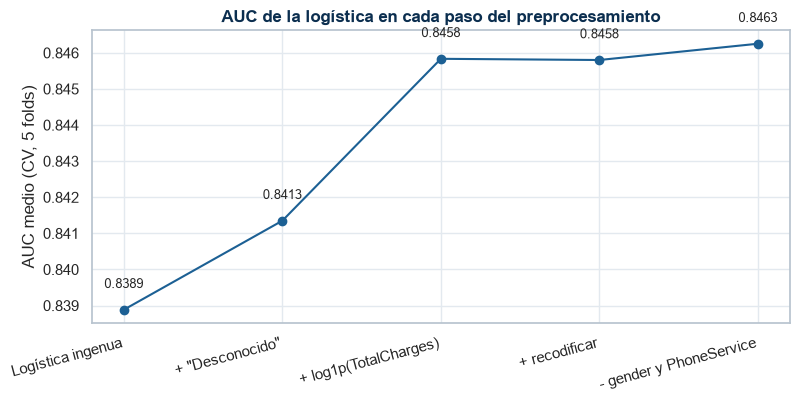

In [17]:
camino = pd.Series({'Logística ingenua': auc_ingenua.mean(), '+ "Desconocido"': auc_desconocido.mean(),   # AUC de la base y del paso 1
                    '+ log1p(TotalCharges)': auc_log.mean(), '+ recodificar': auc_recod.mean(),   # AUC de los pasos 2 y 3
                    '- gender y PhoneService': auc_sin2.mean()})   # AUC medio en cada paso
fig, ax = plt.subplots(figsize=(9, 3.8))                    # figura
ax.plot(range(len(camino)), camino.values, marker='o', color=AZUL_UTN)   # camino del AUC
for i, v in enumerate(camino.values):                       # anoto cada valor
    ax.text(i, v + 0.0006, f'{v:.4f}', ha='center', fontsize=9)   # AUC arriba del punto
ax.set_xticks(range(len(camino)))                           # una marca por paso
ax.set_xticklabels(camino.index, rotation=15, ha='right')   # nombres de los pasos
ax.set_ylabel('AUC medio (CV, 5 folds)')                    # eje y
ax.set_title('AUC de la logística en cada paso del preprocesamiento')   # título
guardar_figura('camino_preprocesamiento')                   # guardo el PNG
plt.show()                                                  # muestro la figura

El gráfico resume el camino: el AUC sube de 0,8389 a 0,8463 y casi toda la mejora viene de los dos primeros pasos.

Fijamos ahora el preprocesamiento elegido, `PREP`, que usan todos los modelos desde acá. Lo ajustamos una vez con train solo para obtener los nombres de las columnas que genera, que necesitamos para leer coeficientes y loadings. Esperamos 42 columnas.

In [18]:
PREP = armar_preprocesador(excluir=EXCLUIR)                 # el preprocesamiento elegido
NOMBRES_COLS = PREP.fit(X_train).get_feature_names_out()    # nombres de las columnas que salen
nombres_cortos = [n.split('__')[1] for n in NOMBRES_COLS]   # sin el prefijo del bloque (num__, cat__)
print('El preprocesamiento elegido entrega', len(NOMBRES_COLS), 'columnas')   # cantidad de columnas
print(', '.join(nombres_cortos))                            # nombres de las columnas, en orden

El preprocesamiento elegido entrega 42 columnas
tenure, MonthlyCharges, TotalCharges, SeniorCitizen_Desconocido, SeniorCitizen_No, SeniorCitizen_Yes, Partner_Desconocido, Partner_No, Partner_Yes, Dependents_Desconocido, Dependents_No, Dependents_Yes, MultipleLines_Desconocido, MultipleLines_No, MultipleLines_No phone service, MultipleLines_Yes, InternetService_DSL, InternetService_Desconocido, InternetService_Fiber optic, InternetService_No, OnlineSecurity_Desconocido, OnlineSecurity_No, OnlineSecurity_Yes, OnlineBackup_Desconocido, OnlineBackup_No, OnlineBackup_Yes, DeviceProtection_Yes, TechSupport_Yes, StreamingTV_Yes, StreamingMovies_Yes, Contract_Desconocido, Contract_Month-to-month, Contract_One year, Contract_Two year, PaperlessBilling_Desconocido, PaperlessBilling_No, PaperlessBilling_Yes, PaymentMethod_Bank transfer (automatic), PaymentMethod_Credit card (automatic), PaymentMethod_Desconocido, PaymentMethod_Electronic check, PaymentMethod_Mailed check


Las 42 columnas son `tenure` y `MonthlyCharges` escaladas, `log1p(TotalCharges)` escalada y 39 dummies. Las variables con faltantes suman una dummy "Desconocido", y las binarias sin faltantes quedan en una sola columna por `drop='if_binary'`.

## 5.4 Variantes que no mejoraron

Probamos cinco ideas más que el EDA dejó abiertas, cada una contra el preprocesamiento elegido. Son quitar `TotalCharges` (decisión 12), agregar `n_adicionales` o los tramos de `tenure` (decisión 15), imputar las numéricas con `KNNImputer` sobre los datos escalados (decisión 8, como sensibilidad) y usar `class_weight='balanced'` (la alternativa al umbral de la decisión 13).

`KNNImputer` completa cada faltante con el promedio de los 10 clientes más parecidos, por eso necesita las numéricas escaladas antes. `class_weight='balanced'` pondera a cada cliente en forma inversamente proporcional a la frecuencia de su clase, de modo que las bajas pesan más en el ajuste. Cada variante se compara fold por fold contra el preprocesamiento elegido y la tabla final reúne los cinco veredictos. Esperamos empates o pérdidas, porque el EDA no veía en ninguna una ganancia clara.

In [19]:
variantes = {                                               # cada variante cambia una cosa respecto del preprocesamiento elegido
    'sin TotalCharges': logistica(armar_preprocesador(excluir=EXCLUIR, sin_total=True)),   # sin la variable TotalCharges
    '+ n_adicionales': logistica(armar_preprocesador(excluir=EXCLUIR, n_adicionales=True)),   # con el conteo de adicionales
    '+ tramos de tenure': logistica(armar_preprocesador(excluir=EXCLUIR, tramos=True)),   # con tramos de antigüedad
    'KNNImputer en numéricas': logistica(armar_preprocesador(excluir=EXCLUIR, knn_numericas=True)),   # KNNImputer en lugar de la mediana
    "class_weight='balanced'": logistica(armar_preprocesador(excluir=EXCLUIR), class_weight='balanced'),   # reponderación de las clases
}                                                           # fin de las variantes
for nombre, modelo in variantes.items():                    # evalúo cada variante con los mismos folds
    comparar(nombre, evaluar_cv(modelo), auc_sin2, 'elegido')   # comparo contra el preprocesamiento elegido
tabla_variantes = pd.DataFrame(experimentos[-len(variantes):]).set_index('experimento')   # las cinco variantes
tabla_variantes[['AUC medio', 'diferencia', 'EE dif.', 'folds que gana', 'veredicto']]   # muestro la tabla

sin TotalCharges                                 AUC 0.8410 ± 0.0110 | vs elegido: -0.0053 (EE 0.0008, gana 0/5) -> empeora
+ n_adicionales                                  AUC 0.8463 ± 0.0103 | vs elegido: +0.0001 (EE 0.0000, gana 5/5) -> empate


+ tramos de tenure                               AUC 0.8457 ± 0.0102 | vs elegido: -0.0005 (EE 0.0003, gana 2/5) -> empate
KNNImputer en numéricas                          AUC 0.8459 ± 0.0096 | vs elegido: -0.0003 (EE 0.0005, gana 3/5) -> empate


class_weight='balanced'                          AUC 0.8459 ± 0.0102 | vs elegido: -0.0004 (EE 0.0001, gana 0/5) -> empate


,AUC medio,diferencia,EE dif.,folds que gana,veredicto
experimento,,,,,
sin TotalCharges,0.8410,-0.0053,0.0008,0,empeora
+ n_adicionales,0.8463,0.0001,0.0000,5,empate
+ tramos de tenure,0.8457,-0.0005,0.0003,2,empate
KNNImputer en numéricas,0.8459,-0.0003,0.0005,3,empate
class_weight='balanced',0.8459,-0.0004,0.0001,0,empate


| Variante | Diferencia | Lectura |
|---|---|---|
| Sin `TotalCharges` | -0,0053, pierde en los 5 folds | Empeora. Aunque su correlación con `tenure` es 0,83, `log1p(TotalCharges)` combina antigüedad y gasto en una escala que sigue mejor la caída del riesgo. La colinealidad afecta sobre todo la lectura de los coeficientes y poco la predicción (James et al., 2023, sec. 3.3.3). |
| `+ n_adicionales` | +0,0001, gana en los 5 folds | Empate por el piso de una milésima. La cuenta es la suma de dummies "Yes" que el modelo ya tiene, así que no agrega información; la diferencia mínima viene de cómo la L2 reparte el peso. Es el caso que justifica el piso. |
| `+ tramos de tenure` | -0,0005 | Empate. `log1p(TotalCharges)` ya captura la no linealidad de la antigüedad. |
| `KNNImputer` en numéricas | -0,0003 | Empate. Después de las reglas R1 a R9 quedan pocos faltantes en `tenure` y `MonthlyCharges`, y un mejor imputador casi no se nota. |
| `class_weight='balanced'` | -0,0004, pierde en los 5 folds | Empate en AUC, que mide orden. Reponderar desplaza las probabilidades hacia arriba y las descalibra, lo que invalida el umbral teórico de la sección 7. |

> **Decisión ML8:** mantener `TotalCharges`, no agregar `n_adicionales` ni tramos de `tenure`, imputar las numéricas con la mediana y no usar `class_weight`.
>
> **Justificación:** ninguna variante mejora de forma consistente y relevante, y quitar `TotalCharges` empeora. Las que empatan suman columnas, un imputador más costoso o probabilidades descalibradas, así que por la regla de la sección 3 nos quedamos con la versión más simple. El desbalance de clases lo resolvemos con el umbral por costos (Murphy, 2022, sec. 5.1.4.4).

# 6. Comparación de modelos

Con el preprocesamiento fijo, comparamos seis familias que hacen supuestos distintos sobre la forma del problema. Cada una busca sus hiperparámetros con `GridSearchCV`, con los folds comunes y por AUC. Las grillas son chicas a propósito, porque con 5.634 clientes una búsqueda más amplia termina ajustando el ruido de los folds. Como contrapartida, varias quedan con el óptimo en un borde de la grilla, y lo revisamos en la sección 6.4.

El preprocesamiento se eligió en la sección 5 con la logística y lo aplicamos igual a todas las familias. Eso puede favorecerla levemente: `log1p` o la recodificación se adoptaron porque mejoraban a un modelo lineal, y un árbol o una red quizás rendirían algo más con otras opciones. Para los árboles la diferencia debería ser chica, porque `log1p` no cambia el orden de los valores.

| Modelo | Hiperparámetros buscados | Por qué lo incluimos |
|---|---|---|
| Regresión logística | `C` (L2) | El EDA sugiere efectos casi aditivos en log-odds (James et al., 2023, sec. 4.3) |
| KNN | `K`, pesos | No supone ninguna forma; referencia no paramétrica (Cover y Hart, 1967) |
| Árbol de decisión | profundidad, hoja mínima | Captura interacciones solo, con alta varianza (Breiman et al., 1984) |
| Random Forest | hoja mínima, variables por corte | Reduce la varianza del árbol promediando (Breiman, 2001) |
| Gradient boosting | tasa, profundidad, árboles, L2 | Suele rendir mejor en datos tabulares (Friedman, 2001; Ke et al., 2017) |
| Red neuronal (MLP) | neuronas, `alpha` | Puede aprender formas no lineales arbitrarias (Géron, 2022, cap. 10) |

Usamos `HistGradientBoostingClassifier` y `MLPClassifier` de scikit-learn para que todos los modelos compartan el mismo pipeline, los mismos folds y la misma búsqueda.

## 6.1 Búsqueda de hiperparámetros

Un hiperparámetro es una opción del modelo que no se aprende de los datos al entrenar, como el `C` de la logística o la profundidad de un árbol. `GridSearchCV` prueba todas las combinaciones de una grilla con los folds comunes, se queda con la de mayor AUC medio y la reentrena con todo train. La función `buscar` hace eso para cada familia e imprime una línea con el AUC de validación, el AUC sobre los folds de entrenamiento, la cantidad de combinaciones, el tiempo y los hiperparámetros elegidos.

Pedimos también el AUC de entrenamiento (`return_train_score=True`) porque su distancia con el de validación indica sobreajuste. `folds_de` extrae los cinco AUC de la mejor combinación, que usamos en las comparaciones pareadas. Esperamos AUC parecidos entre las familias flexibles y la logística, y brechas mayores en los modelos de árboles. Al final guardamos el `C` elegido para la logística, que reaparece en las secciones 8 y 10.

In [20]:
def buscar(nombre, modelo, grilla):   # GridSearchCV con los folds comunes
    # busca los hiperparámetros por AUC, imprime el mejor resultado y devuelve la búsqueda ajustada
    inicio = time.time()                                    # para medir el tiempo
    busqueda = GridSearchCV(Pipeline([('prep', PREP), ('modelo', modelo)]), grilla, cv=CV,   # pipeline y grilla con los folds comunes
                            scoring='roc_auc', n_jobs=-1, return_train_score=True)   # búsqueda en grilla
    busqueda.fit(X_train, y_train)                          # todas las combinaciones (y la mejor, reajustada con todo train)
    folds = folds_de(busqueda)                              # AUC por fold de la mejor combinación
    r, i = busqueda.cv_results_, busqueda.best_index_       # resultados y mejor posición
    print(f'{nombre:20s} AUC {folds.mean():.4f} ± {folds.std(ddof=1):.4f} | train {r["mean_train_score"][i]:.4f} | '   # AUC de validación ± desvío y de train
          f'{len(r["params"])} combinaciones, {time.time() - inicio:.1f} s | {busqueda.best_params_}')   # resumen
    return busqueda                                         # devuelvo la búsqueda


def folds_de(busqueda):   # AUC por fold de la mejor combinación de una búsqueda
    # extrae los 5 AUC de validación de la mejor combinación
    r, i = busqueda.cv_results_, busqueda.best_index_       # resultados y mejor posición
    return np.array([r[f'split{j}_test_score'][i] for j in range(5)])   # AUC por fold


busquedas = {}                                              # acá guardo cada búsqueda
busquedas['Logística'] = buscar('Logística', LogisticRegression(max_iter=2000),   # logística L2
                                {'modelo__C': [0.01, 0.03, 0.1, 0.3, 1, 3, 10]})   # 7 valores de C en escala logarítmica
busquedas['KNN'] = buscar('KNN', KNeighborsClassifier(),    # K vecinos
                          {'modelo__n_neighbors': [5, 15, 25, 51, 101, 151, 201],   # K de 5 a 201
                           'modelo__weights': ['uniform', 'distance']})   # K impar; peso uniforme o por distancia
busquedas['Árbol'] = buscar('Árbol', DecisionTreeClassifier(random_state=SEED),   # árbol con semilla
                            {'modelo__max_depth': [3, 4, 5, 6, 8],   # profundidad máxima
                             'modelo__min_samples_leaf': [20, 50, 100]})   # profundidad y tamaño mínimo de hoja
busquedas['Random Forest'] = buscar('Random Forest',        # Random Forest
                                    RandomForestClassifier(n_estimators=500, random_state=SEED, n_jobs=1),   # un núcleo: GridSearchCV ya paraleliza
                                    {'modelo__min_samples_leaf': [5, 10, 20, 40],   # tamaño mínimo de hoja
                                     'modelo__max_features': ['sqrt', 0.3]})   # hojas y variables por corte
busquedas['Boosting'] = buscar('Boosting', HistGradientBoostingClassifier(early_stopping=False, random_state=SEED),   # boosting sin parada temprana
                               {'modelo__learning_rate': [0.03, 0.05, 0.1],   # tasa de aprendizaje
                                'modelo__max_depth': [2, 3],   # profundidad de cada árbol
                                'modelo__max_iter': [100, 300],   # cantidad de árboles
                                'modelo__l2_regularization': [0, 1]})   # tasa, profundidad, cantidad de árboles y L2
busquedas['Red neuronal'] = buscar('Red neuronal', MLPClassifier(max_iter=2000, random_state=SEED),   # MLP con semilla
                                   {'modelo__hidden_layer_sizes': [(8,), (16,), (32,)],   # neuronas de la capa oculta
                                    'modelo__alpha': [0.1, 1, 10]})   # una capa oculta y regularización L2
C_LOG = busquedas['Logística'].best_params_['modelo__C']    # el C elegido para la logística
print('C elegido para la logística:', C_LOG)                # penalización L2 del modelo final

Logística            AUC 0.8463 ± 0.0103 | train 0.8511 | 7 combinaciones, 0.8 s | {'modelo__C': 1}


KNN                  AUC 0.8397 ± 0.0103 | train 0.8441 | 14 combinaciones, 2.9 s | {'modelo__n_neighbors': 151, 'modelo__weights': 'uniform'}


Árbol                AUC 0.8110 ± 0.0119 | train 0.8569 | 15 combinaciones, 1.2 s | {'modelo__max_depth': 6, 'modelo__min_samples_leaf': 20}


Random Forest        AUC 0.8437 ± 0.0122 | train 0.8801 | 8 combinaciones, 15.0 s | {'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 20}


Boosting             AUC 0.8464 ± 0.0114 | train 0.8624 | 24 combinaciones, 6.7 s | {'modelo__l2_regularization': 1, 'modelo__learning_rate': 0.1, 'modelo__max_depth': 2, 'modelo__max_iter': 100}


Red neuronal         AUC 0.8461 ± 0.0105 | train 0.8565 | 9 combinaciones, 7.4 s | {'modelo__alpha': 1, 'modelo__hidden_layer_sizes': (32,)}
C elegido para la logística: 1


## 6.2 KNN: sesgo y varianza según K

KNN predice para cada cliente la proporción de bajas entre sus `K` vecinos más cercanos de train. Con `K` chico, la predicción sigue de cerca a pocos clientes y el modelo tiene mucha varianza: memoriza train y generaliza mal. Con `K` grande promedia más clientes y se vuelve más estable, a costa de sesgo. Graficamos el AUC de entrenamiento y de validación para cada `K` con pesos uniformes. Esperamos que las curvas empiecen separadas y se acerquen a medida que `K` crece.

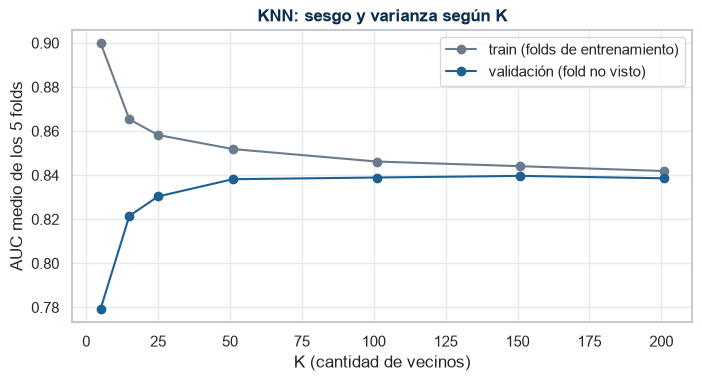

K                 5      15     25     51     101    151    201
AUC train      0.9000 0.8654 0.8582 0.8519 0.8462 0.8441 0.8419
AUC validación 0.7793 0.8215 0.8304 0.8382 0.8389 0.8397 0.8386


In [21]:
res_knn = pd.DataFrame(busquedas['KNN'].cv_results_)         # todas las combinaciones de KNN
res_knn = res_knn[res_knn['param_modelo__weights'] == 'uniform']   # me quedo con el peso uniforme
fig, ax = plt.subplots(figsize=(8, 3.8))                    # figura
ax.plot(res_knn['param_modelo__n_neighbors'], res_knn['mean_train_score'], marker='o', color=GRIS,   # AUC de train según K
        label='train (folds de entrenamiento)')             # AUC sobre los clientes que el modelo vio
ax.plot(res_knn['param_modelo__n_neighbors'], res_knn['mean_test_score'], marker='o', color=AZUL_UTN,   # AUC de validación según K
        label='validación (fold no visto)')                 # AUC sobre clientes nuevos
ax.set_xlabel('K (cantidad de vecinos)')                    # eje x
ax.set_ylabel('AUC medio de los 5 folds')                   # eje y
ax.set_title('KNN: sesgo y varianza según K')               # título
ax.legend()                                                 # leyenda
guardar_figura('knn_sesgo_varianza')                        # guardo el PNG
plt.show()                                                  # muestro la figura
print(res_knn[['param_modelo__n_neighbors', 'mean_train_score', 'mean_test_score']]   # columnas del gráfico
      .set_axis(['K', 'AUC train', 'AUC validación'], axis=1).set_index('K').round(4).T)   # valores del gráfico

La logística, el boosting y la red neuronal quedan en 0,846. Random Forest llega a 0,844, KNN a 0,840 y el árbol a 0,811. El gráfico de KNN muestra el compromiso entre sesgo y varianza: con `K = 5` el AUC de train es 0,90 y el de validación 0,78. A medida que `K` crece, las curvas se acercan y la validación se estabiliza cerca de 0,84 a partir de unos 50 vecinos (James et al., 2023, sec. 2.2.3). Que KNN necesite tantos vecinos es coherente con lo poco informativa que resulta una distancia entre clientes descriptos casi solo con dummies.

## 6.3 Faltantes e interacciones en el boosting

Dos preguntas que el EDA dejó para la validación cruzada se responden con el boosting. La primera es si conviene que los árboles manejen los `NaN` de las numéricas en lugar de imputar la mediana; la segunda, si las interacciones aportan. Para la segunda usamos un boosting de profundidad 1, que solo puede sumar efectos de una variable por vez y es, por lo tanto, aditivo como la logística.

El boosting arma una secuencia de árboles chicos, donde cada uno corrige los errores de los anteriores. `HistGradientBoostingClassifier` acepta `NaN` y aprende hacia qué rama mandarlos, así que para la primera pregunta basta con sacar la mediana del preprocesador y mantener sus hiperparámetros. Con faltantes MCAR esperamos un empate en los dos casos. Si el churn fuera casi aditivo, como sugiere el EDA, el boosting de profundidad 1 tampoco debería perder AUC.

In [22]:
boosting_nan = Pipeline([('prep', armar_preprocesador(excluir=EXCLUIR, imputar_num=False)),   # preprocesador sin imputar numéricas
                         ('modelo', HistGradientBoostingClassifier(early_stopping=False, random_state=SEED))])   # sin imputar numéricas
boosting_nan.set_params(**busquedas['Boosting'].best_params_)  # mismos hiperparámetros que el mejor boosting
_ = comparar('Boosting con NaN nativos en numéricas', evaluar_cv(boosting_nan),   # AUC por fold con NaN nativos
             folds_de(busquedas['Boosting']), 'boosting imputando')   # comparación pareada

boosting_aditivo = buscar('Boosting prof. 1', HistGradientBoostingClassifier(early_stopping=False, max_depth=1, random_state=SEED),   # boosting de un solo corte por árbol
                          {'modelo__learning_rate': [0.05, 0.1, 0.2],   # tasa de aprendizaje
                           'modelo__max_iter': [100, 300],   # cantidad de árboles
                           'modelo__l2_regularization': [0, 1, 10]})   # árboles de un solo corte: modelo aditivo
_ = comparar('Boosting de profundidad 1 (sin interacciones)', folds_de(boosting_aditivo),   # AUC por fold del boosting aditivo
             folds_de(busquedas['Boosting']), 'boosting elegido')   # ¿pierde algo sin interacciones?

Boosting con NaN nativos en numéricas            AUC 0.8461 ± 0.0111 | vs boosting imputando: -0.0002 (EE 0.0003, gana 3/5) -> empate


Boosting prof. 1     AUC 0.8465 ± 0.0113 | train 0.8562 | 18 combinaciones, 2.5 s | {'modelo__l2_regularization': 1, 'modelo__learning_rate': 0.1, 'modelo__max_iter': 300}
Boosting de profundidad 1 (sin interacciones)    AUC 0.8465 ± 0.0113 | vs boosting elegido: +0.0002 (EE 0.0006, gana 2/5) -> empate


Los dos experimentos empatan. Dejar los `NaN` al boosting no cambia el AUC (-0,0002): con faltantes MCAR (decisión 6 del EDA), el cliente sin dato no tiene un riesgo propio que aprender, y mantenemos la mediana, que sirve para todos los modelos. El boosting de profundidad 1 llega a 0,8465, lo mismo que el de profundidad 2 y que la logística. Un modelo que no puede combinar variables rinde igual que uno que sí, lo cual concuerda con el EDA, donde el odds ratio de la fibra frente a DSL era parecido en los tres tipos de contrato. Como el boosting aditivo puede dibujar además una curva arbitraria para cada variable, el empate indica también que `log1p(TotalCharges)` ya le dio a la logística la no linealidad relevante.

## 6.4 Ensamble y comparación de todos los modelos

Por último, promediamos las probabilidades de la logística y del boosting (voto suave), que se equivocan de formas distintas (Géron, 2022, cap. 7). Cuando los errores de dos modelos no coinciden, el promedio cancela una parte y puede ordenar mejor que cada uno por separado.

Después reunimos los AUC por fold de todos los modelos en una tabla. Para cada uno calculamos la media, el desvío entre folds, el error estándar de la media y la brecha entre train y validación. La regla de un error estándar marca como candidatos a los modelos cuyo AUC medio supera el del mejor menos su error estándar. Imprimimos también las diferencias pareadas del ensamble y del boosting contra la logística. Esperamos varios modelos dentro del límite, separados por milésimas.

In [23]:
mejor_logistica = busquedas['Logística'].best_estimator_    # logística con su mejor C (reajustada con todo train)
mejor_boosting = busquedas['Boosting'].best_estimator_      # boosting con sus mejores hiperparámetros
ensamble = VotingClassifier([('logistica', mejor_logistica), ('boosting', mejor_boosting)],   # los dos modelos ya elegidos
                            voting='soft')                  # promedia las probabilidades de los dos
auc_ensamble = evaluar_cv(ensamble)                         # AUC por fold con los mismos folds

auc_por_fold = {nombre: folds_de(b) for nombre, b in busquedas.items()}   # AUC por fold de cada modelo
auc_por_fold['Ensamble'] = auc_ensamble                     # agrego el ensamble
auc_por_fold['Dummy'] = auc_dummy                           # y la referencia mínima
comparacion = pd.DataFrame({                                # tabla de comparación
    'AUC medio': {n: v.mean() for n, v in auc_por_fold.items()},   # promedio de los 5 folds
    'desvío': {n: v.std(ddof=1) for n, v in auc_por_fold.items()},   # variación entre folds
    'EE': {n: v.std(ddof=1) / np.sqrt(5) for n, v in auc_por_fold.items()},   # error estándar del promedio
    'AUC train': {n: b.cv_results_['mean_train_score'][b.best_index_] for n, b in busquedas.items()},   # ajuste en train
}).sort_values('AUC medio', ascending=False)                # de mejor a peor
comparacion['brecha train - valid.'] = comparacion['AUC train'] - comparacion['AUC medio']   # señal de sobreajuste
mejor = comparacion['AUC medio'].idxmax()                   # el de mayor AUC medio
limite = comparacion.loc[mejor, 'AUC medio'] - comparacion.loc[mejor, 'EE']   # regla de un error estándar
comparacion['dentro de 1 EE del mejor'] = comparacion['AUC medio'] >= limite   # candidatos empatados
print(f'Mejor AUC medio: {mejor} ({comparacion.loc[mejor, "AUC medio"]:.4f}); límite de 1 EE: {limite:.4f}')   # resultado
for otro in ['Ensamble', 'Boosting']:                       # diferencias pareadas contra la logística
    dif = auc_por_fold[otro] - auc_por_fold['Logística']    # fold por fold
    print(f'{otro} - logística: {dif.mean():+.4f} (EE {dif.std(ddof=1) / np.sqrt(5):.4f}), gana en {(dif > 0).sum()}/5 folds')   # resultado

Mejor AUC medio: Ensamble (0.8478); límite de 1 EE: 0.8430
Ensamble - logística: +0.0016 (EE 0.0008), gana en 4/5 folds
Boosting - logística: +0.0001 (EE 0.0016), gana en 2/5 folds


El gráfico muestra el AUC de cada fold en cada modelo. Cada línea gris une los AUC de un mismo fold en todos los modelos, y el punto naranja es la media de los cinco folds. Si las líneas suben y bajan juntas, la dificultad depende más del fold que del modelo, y eso justifica comparar de forma pareada. La línea punteada es el límite de la regla de un error estándar. Debajo mostramos la tabla completa.

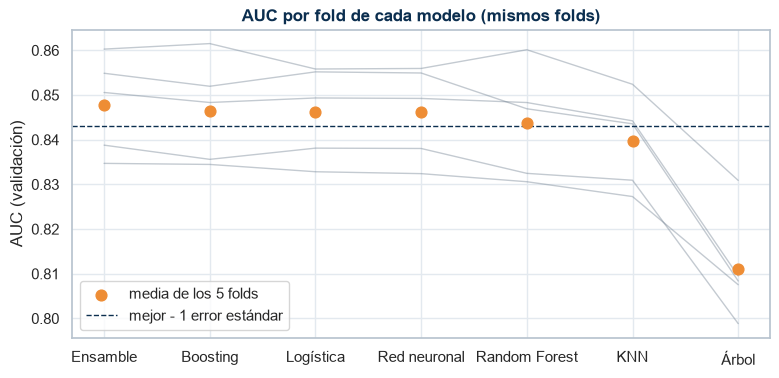

,AUC medio,desvío,EE,AUC train,brecha train - valid.,dentro de 1 EE del mejor
Ensamble,0.8478,0.0108,0.0048,NaN,NaN,True
Boosting,0.8464,0.0114,0.0051,0.8624,0.0161,True
Logística,0.8463,0.0103,0.0046,0.8511,0.0048,True
Red neuronal,0.8461,0.0105,0.0047,0.8565,0.0104,True
Random Forest,0.8437,0.0122,0.0055,0.8801,0.0364,True
KNN,0.8397,0.0103,0.0046,0.8441,0.0044,False
Árbol,0.8110,0.0119,0.0053,0.8569,0.0458,False
Dummy,0.5000,0.0000,0.0000,NaN,NaN,False


In [24]:
fig, ax = plt.subplots(figsize=(9, 4))                      # figura
orden = [n for n in comparacion.index if n != 'Dummy']      # modelos sin la Dummy (está en 0,5)
for j in range(5):                                          # una línea gris por fold: comparación pareada
    ax.plot(orden, [auc_por_fold[n][j] for n in orden], color=GRIS, alpha=0.4, lw=1)   # AUC de ese fold en cada modelo
ax.scatter(orden, [auc_por_fold[n].mean() for n in orden], color=NARANJA, s=60, zorder=3, label='media de los 5 folds')   # medias
ax.axhline(limite, color=AZUL_OSCURO, ls='--', lw=1, label='mejor - 1 error estándar')   # regla de un EE
ax.set_ylabel('AUC (validación)')                           # eje y
ax.set_title('AUC por fold de cada modelo (mismos folds)')  # título
ax.legend(loc='lower left')                                 # leyenda
guardar_figura('comparacion_modelos')                       # guardo el PNG
plt.show()                                                  # muestro la figura
comparacion                                                 # muestro la tabla

Para ilustrar cómo decide un árbol, ajustamos uno de solo 3 niveles con todo train y lo dibujamos. No es un modelo candidato, porque el elegido por la búsqueda tiene profundidad 6. Cada nodo muestra la regla de corte, la proporción de clientes que llega a él y la proporción de cada clase. Esperamos que los primeros cortes usen las variables que el EDA marcó como más asociadas al churn.

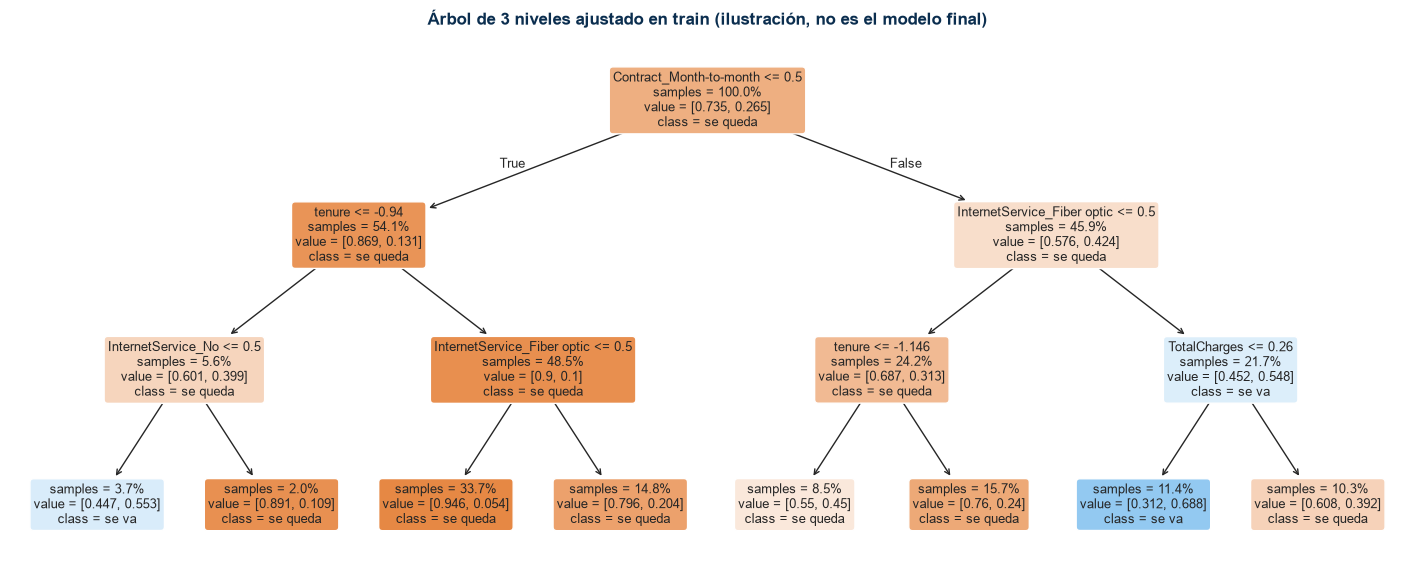

In [25]:
arbol_chico = Pipeline([('prep', PREP), ('modelo', DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, random_state=SEED))])   # árbol de 3 niveles
arbol_chico.fit(X_train, y_train)                           # lo ajusto con todo train, solo como ilustración
fig, ax = plt.subplots(figsize=(18, 7))                     # figura ancha
plot_tree(arbol_chico.named_steps['modelo'], feature_names=nombres_cortos, class_names=['se queda', 'se va'],   # árbol con nombres de columnas y clases
          filled=True, rounded=True, impurity=False, proportion=True, fontsize=9, ax=ax)   # dibujo el árbol
ax.set_title('Árbol de 3 niveles ajustado en train (ilustración, no es el modelo final)')   # título
guardar_figura('arbol_3_niveles')                           # guardo el PNG
plt.show()                                                  # muestro la figura

Las líneas grises suben y bajan juntas: hay folds más fáciles y más difíciles para todos, y por eso comparamos de forma pareada. El AUC de cada modelo corresponde a su mejor combinación, elegida en los mismos folds en que se mide, lo que lo vuelve algo optimista. Con grillas de 7 a 24 combinaciones el sesgo es chico, y el test de la sección 9 lo controla (Géron, 2022, cap. 2).

Hay que reconocer que varias búsquedas eligieron un valor en el borde de su grilla, de modo que no sabemos si un valor más extremo rendiría más. En el boosting los cuatro hiperparámetros quedan en un borde: tasa 0,1, profundidad 2, 100 árboles y L2 igual a 1. La red neuronal elige 32 neuronas, el máximo probado, y el árbol una hoja mínima de 20, el mínimo. Dos atenuantes acotan el problema. El boosting de profundidad 1 explora por debajo del borde de profundidad y empata (0,8465). Además, los cinco candidatos quedan en un rango estrecho, de 0,8437 a 0,8478, que no sugiere una mejora grande escondida fuera de las grillas.

El patrón de resultados es coherente con una estructura casi aditiva. El árbol solo queda último y con la mayor brecha entre train y validación (0,046). Random Forest reduce esa varianza, pero no supera a la logística y mantiene una brecha de 0,036. El boosting y la red neuronal empatan con la logística aun pudiendo aprender interacciones y no linealidades. El ensamble es el único que se separa: +0,0016 sobre la logística, en 4 de los 5 folds, con un error estándar de 0,0008.

Con la regla de los modelos (un error estándar del AUC medio, 0,0048 para el ensamble), el ensamble y la logística empatan. Si en cambio le aplicáramos la regla pareada del preprocesamiento, la diferencia de +0,0016 quedaría justo en el límite de dos errores estándar pareados (2 × 0,0008) y supera el piso de una milésima. Es decir, con un criterio más permisivo el ensamble podría haberse adoptado. Mantenemos la regla fijada en la sección 3, y en un caso tan ajustado desempata la interpretabilidad de la logística.

El árbol de 3 niveles, que dibujamos solo para ilustrar, corta primero por el contrato mes a mes y después por la antigüedad (escalada) y el tipo de internet. Es el perfil de riesgo del EDA, encontrado por un algoritmo que no vio esos gráficos.

> **Decisión ML9:** el modelo final es la regresión logística con el preprocesamiento de ML4 a ML8 y el `C` elegido por validación cruzada. El ensamble logística + boosting se evalúa en test como contraste, decidido de antemano.
>
> **Justificación:** el ensamble, el boosting, la logística, la red neuronal y Random Forest quedan dentro de un error estándar del mejor, y entre ellos la logística es el más simple (James et al., 2023, sec. 6.1.3). Usamos esta regla, y no la pareada, porque es la estándar y la fijamos antes de ver resultados; con la pareada, el ensamble (+0,0016, EE pareado 0,0008, gana 4 de 5 folds) quedaba en el límite. En ese margen desempata que la logística se interpreta con odds ratios. Que se ajuste minimizando la entropía cruzada no la distingue, porque el boosting y la red también lo hacen; su calibración la verificamos en la sección 7. También tiene la menor brecha entre train y validación de los candidatos (0,005, contra 0,010 de la red, 0,016 del boosting y 0,036 de Random Forest). Llevar el ensamble a test permite medir cuánto cuesta elegir el modelo simple.

# 7. Umbral de decisión por costos

Con la matriz de la decisión 18, perder un cliente cuesta más de 7 veces lo que cuesta la oferta, así que el umbral de 0,5 de `predict` no tiene relación con el problema. Para elegir el umbral sin tocar el test usamos probabilidades fuera del fold. El umbral teórico supone además probabilidades calibradas, y lo controlamos comparando, por deciles de probabilidad predicha, la probabilidad media con la tasa real de churn (Niculescu-Mizil y Caruana, 2005).

## 7.1 Probabilidades fuera del fold

Con `cross_val_predict`, cada cliente de train recibe la probabilidad que le asigna el modelo entrenado en los otros cuatro folds, es decir, un modelo que no lo vio. Así obtenemos 5.634 probabilidades honestas sin usar el test. Esperamos un AUC parecido al 0,846 de la validación cruzada y una probabilidad media cercana a la tasa real de bajas.

In [26]:
prob_oof = cross_val_predict(mejor_logistica, X_train, y_train, cv=CV, method='predict_proba')[:, 1]   # probabilidad fuera del fold
print(f'AUC fuera del fold: {roc_auc_score(y_train, prob_oof):.4f}')   # coincide con el de la CV
print(f'Probabilidad media predicha: {prob_oof.mean():.4f} | tasa real de churn en train: {y_train.mean():.4f}')   # calibración global

AUC fuera del fold: 0.8459
Probabilidad media predicha: 0.2652 | tasa real de churn en train: 0.2654


El AUC fuera del fold (0,8459) queda muy cerca del 0,8463 de la validación cruzada, y la probabilidad media (0,2652) coincide con la tasa real (0,2654). En promedio, el modelo no sobreestima ni subestima el riesgo. Ese control es global, y podría esconder errores que se compensan entre clientes de riesgo bajo y alto.

## 7.2 Calibración por decil

Un modelo está calibrado si, entre los clientes a los que asigna una probabilidad cercana a `p`, se va más o menos una proporción `p`. Para verlo, ordenamos a los clientes de train por su probabilidad fuera del fold y los dividimos en diez grupos del mismo tamaño (deciles). En cada decil comparamos la probabilidad media con la tasa real de bajas y calculamos la diferencia (tasa real menos probabilidad).

Nos interesan en especial los deciles cuya probabilidad media está entre 0,10 y 0,20, porque el umbral de 0,134 corta en esa zona. Ahí un error de calibración cambiaría a quién se le ofrece la retención. Imprimimos la diferencia máxima en esos deciles y, como referencia, la de toda la tabla.

In [27]:
deciles = pd.qcut(prob_oof, 10, labels=False)               # decil de probabilidad de cada cliente
calibracion = pd.DataFrame({'prob. predicha media': pd.Series(prob_oof).groupby(deciles).mean(),   # probabilidad media por decil
                            'tasa real de churn': pd.Series(y_train).groupby(deciles).mean(),   # tasa real por decil
                            'clientes': pd.Series(y_train).groupby(deciles).size()})   # por decil
calibracion.index.name = 'decil'                            # nombre de las filas
tabla_calibracion = calibracion.assign(diferencia=calibracion['tasa real de churn'] - calibracion['prob. predicha media'])   # tasa real menos probabilidad media
cerca_umbral = tabla_calibracion[tabla_calibracion['prob. predicha media'].between(0.10, 0.20)]   # deciles con probabilidad media entre 0,10 y 0,20
print(f'Deciles con probabilidad media entre 0,10 y 0,20: {list(cerca_umbral.index)} | '   # deciles cercanos al umbral
      f'diferencia máxima (absoluta): {cerca_umbral["diferencia"].abs().max():.4f}')   # calibración cerca del umbral
print(f'Diferencia máxima en los diez deciles: {tabla_calibracion["diferencia"].abs().max():.4f} '   # mayor diferencia de la tabla
      f'(decil {tabla_calibracion["diferencia"].abs().idxmax()})')   # referencia para toda la tabla
tabla_calibracion                                           # muestro la tabla

Deciles con probabilidad media entre 0,10 y 0,20: [4] | diferencia máxima (absoluta): 0.0075
Diferencia máxima en los diez deciles: 0.0284 (decil 8)


,prob. predicha media,tasa real de churn,clientes,diferencia
decil,,,,
0,0.0096,0.0177,564,0.0081
1,0.0256,0.0231,563,-0.0025
2,0.0509,0.0657,563,0.0148
3,0.0878,0.0816,564,-0.0062
4,0.1461,0.1385,563,-0.0075
5,0.2203,0.2220,563,0.0017
6,0.3123,0.3174,564,0.0050
7,0.4399,0.4405,563,0.0006
8,0.5861,0.5577,563,-0.0284


En la zona del umbral, la calibración es buena. El único decil con probabilidad media entre 0,10 y 0,20 es el 4: el modelo predice 14,6% y se va el 13,9%, una diferencia de 0,75 puntos. Con 563 clientes por decil, el error estándar de una tasa cercana a 0,14 ronda 1,5 puntos, así que esa diferencia está dentro del ruido de muestreo.

La mayor diferencia de la tabla aparece en el decil 8, donde el modelo predice 58,6% y se va el 55,8% (2,8 puntos). Ese decil queda muy por encima del umbral, de modo que el desvío no cambia a quién se le ofrece la retención. En los demás deciles las diferencias son de 1,6 puntos o menos.

El gráfico muestra la misma tabla. Cada punto es un decil, con su probabilidad media en el eje horizontal y su tasa real en el vertical. Si el modelo está calibrado, los puntos caen cerca de la diagonal.

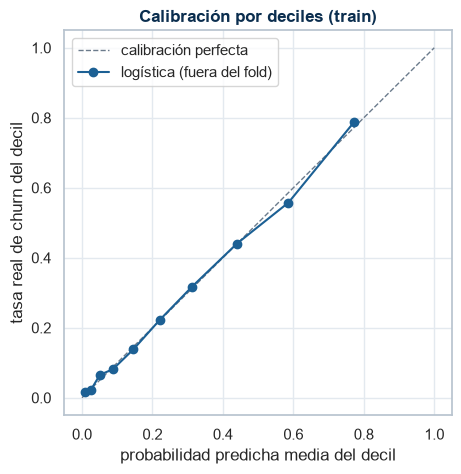

In [28]:
fig, ax = plt.subplots(figsize=(5, 5))                      # figura cuadrada
ax.plot([0, 1], [0, 1], color=GRIS, ls='--', lw=1, label='calibración perfecta')   # diagonal
ax.plot(calibracion['prob. predicha media'], calibracion['tasa real de churn'], marker='o', color=AZUL_UTN,   # curva de los deciles
        label='logística (fuera del fold)')                 # curva de calibración
ax.set_xlabel('probabilidad predicha media del decil')      # eje x
ax.set_ylabel('tasa real de churn del decil')               # eje y
ax.set_title('Calibración por deciles (train)')             # título
ax.legend()                                                 # leyenda
guardar_figura('calibracion')                               # guardo el PNG
plt.show()                                                  # muestro la figura

Los puntos quedan sobre la diagonal. La logística está calibrada, así que el umbral teórico es aplicable.

## 7.3 Costo según el umbral

Calculamos el costo total en train para cada umbral entre 0,01 y 0,99, con las probabilidades fuera del fold, y lo comparamos con tres estrategias de referencia: no ofrecer a nadie, ofrecer a todos y usar el 0,5 de `predict`. También marcamos la zona de umbrales cuyo costo queda a menos del 1% del mínimo. Esperamos una curva en forma de U, con el umbral teórico cerca del fondo.

Umbrales a menos del 1% del costo mínimo: de 0.10 a 0.18


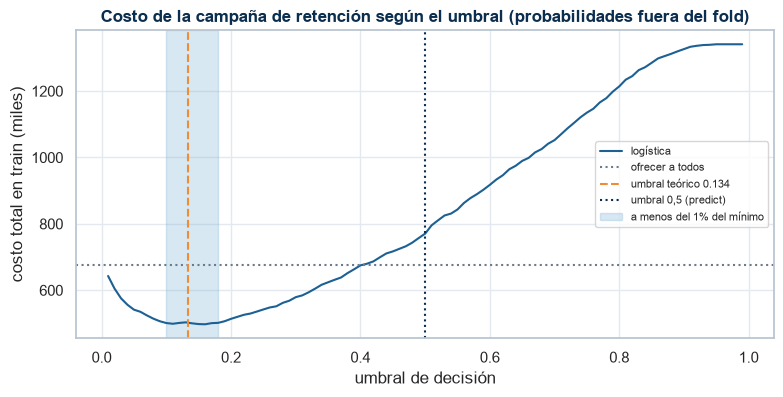

,costo total en train
nadie (no ofrecer),1341015.0000
a todos,676080.0000
"umbral 0,5 (predict)",770517.0000
umbral teórico 0.134,502341.0000
mínimo empírico 0.16,497475.0000


In [29]:
umbrales = np.round(np.arange(0.01, 1.0, 0.01), 2)          # umbrales de 0,01 a 0,99
costos = np.array([costo_total(y_train, prob_oof, u) for u in umbrales])   # costo de cada umbral
umbral_empirico = umbrales[costos.argmin()]                 # el que minimiza el costo en train
cerca = umbrales[costos <= costos.min() * 1.01]             # umbrales a menos del 1% del mínimo

estrategias = pd.Series({                                   # costo de cada estrategia
    'nadie (no ofrecer)': costo_total(y_train, prob_oof, 1.01),   # ningún cliente supera 1,01
    'a todos': costo_total(y_train, prob_oof, 0.0),        # todos superan 0
    'umbral 0,5 (predict)': costo_total(y_train, prob_oof, 0.5),   # el umbral por defecto
    f'umbral teórico {UMBRAL_TEORICO:.3f}': costo_total(y_train, prob_oof, UMBRAL_TEORICO),   # oferta / pérdida
    f'mínimo empírico {umbral_empirico:.2f}': costos.min(),   # el mejor en train
}, name='costo total en train')                             # tabla de estrategias
print(f'Umbrales a menos del 1% del costo mínimo: de {cerca.min():.2f} a {cerca.max():.2f}')   # zona plana

fig, ax = plt.subplots(figsize=(9, 4))                      # figura
ax.plot(umbrales, costos / 1000, color=AZUL_UTN, label='logística')   # curva en U
ax.axhline(estrategias['a todos'] / 1000, color=GRIS, ls=':', label='ofrecer a todos')   # referencia
ax.axvline(UMBRAL_TEORICO, color=NARANJA, ls='--', label=f'umbral teórico {UMBRAL_TEORICO:.3f}')   # umbral teórico
ax.axvline(0.5, color=AZUL_OSCURO, ls=':', label='umbral 0,5 (predict)')   # umbral por defecto
ax.axvspan(cerca.min(), cerca.max(), color=CELESTE, alpha=0.3, label='a menos del 1% del mínimo')   # zona plana
ax.set_xlabel('umbral de decisión')                         # eje x
ax.set_ylabel('costo total en train (miles)')               # eje y
ax.set_title('Costo de la campaña de retención según el umbral (probabilidades fuera del fold)')   # título
ax.legend(fontsize=8)                                       # leyenda
guardar_figura('curva_costo')                               # guardo el PNG
plt.show()                                                  # muestro la figura
estrategias.to_frame()                                      # muestro la tabla

La curva tiene forma de U: con umbrales bajos se gasta en ofertas de más y con umbrales altos se pierden clientes. Con 0,5, el modelo cuesta 770.517, más que ofrecer a todos (676.080). El umbral teórico cuesta 502.341 y cae en la zona plana que va de 0,10 a 0,18, a menos del 1% del mínimo empírico (497.475 en 0,16). Preferimos el teórico porque no está ajustado a estos 5.634 clientes y se recalcula con una división si cambian los costos; dentro de la zona plana, la diferencia con el mínimo empírico es ruido de muestra.

## 7.4 Sensibilidad a los supuestos de costo

Los costos de la decisión 18 son supuestos: 897 es facturación y no margen, y no sabemos qué parte de la pérdida recupera la oferta. Recalculamos el umbral y el ahorro frente a la mejor estrategia sin modelo en doce escenarios. Combinamos cuatro valores de `r` (100%, 75%, 50% y 25% de la pérdida recuperada) con tres costos de oferta (10% del año, 120 y 20% del año). En cada escenario el umbral es $\text{oferta} / (r \cdot \text{pérdida})$. Esperamos que el umbral suba cuando la oferta recupera menos o cuesta más, y que el ahorro se achique.

In [30]:
filas = []                                                  # una fila por escenario
for recuperado in [1.0, 0.75, 0.5, 0.25]:                   # parte de la pérdida que se recupera
    for nombre_oferta, oferta in [('10% del año', 0.10 * PERDIDA), (f'{OFERTA}', OFERTA), ('20% del año', 0.20 * PERDIDA)]:   # costos de la oferta
        umbral = oferta / (recuperado * PERDIDA)            # umbral teórico del escenario
        c_modelo = costo_total(y_train, prob_oof, umbral, oferta=oferta, recuperado=recuperado)   # costo con el modelo
        c_todos = costo_total(y_train, prob_oof, 0.0, oferta=oferta, recuperado=recuperado)       # ofrecer a todos
        c_nadie = costo_total(y_train, prob_oof, 1.01, oferta=oferta, recuperado=recuperado)      # no ofrecer
        filas.append({'se recupera': f'{recuperado:.0%}', 'oferta': nombre_oferta, 'umbral': umbral,   # escenario y umbral
                      'ofertas (% de clientes)': (prob_oof >= umbral).mean() * 100,   # porcentaje de clientes contactados
                      'ahorro vs. mejor sin modelo (%)': (1 - c_modelo / min(c_todos, c_nadie)) * 100})   # resultado del escenario
sensibilidad = pd.DataFrame(filas).set_index(['se recupera', 'oferta'])   # tabla
sensibilidad.round(2)                                       # muestro la tabla

umbral  ofertas (% de clientes)  \
se recupera oferta                                         
100%        10% del año  0.1000                  62.3200   
            120          0.1300                  56.6600   
            20% del año  0.2000                  47.4800   
75%         10% del año  0.1300                  56.7100   
            120          0.1800                  50.4300   
            20% del año  0.2700                  39.4600   
50%         10% del año  0.2000                  47.4800   
            120          0.2700                  39.3300   
            20% del año  0.4000                  27.6500   
25%         10% del año  0.4000                  27.6500   
            120          0.5400                  18.4200   
            20% del año  0.8000                   3.3900   

                         ahorro vs. mejor sin modelo (%)  
se recupera oferta                                        
100%        10% del año                          21.8800  
            120                                  25.7000  
            20% del año                          33.4400  
75%         10% del año                          15.4600  
            120                                  21.1000  
            20% del año                          29.3600  
50%         10% del año                          14.3700  
            120                                  19.5300  
            20% del año                          10.9600  
25%         10% del año                           5.4800  
            120                                   2.5800  
            20% del año                           0.2400

La columna de ahorro se mide contra la mejor de las dos estrategias sin modelo, y esa estrategia no es la misma en todos los escenarios. Para que se vea contra qué base se calcula cada porcentaje, la celda siguiente recalcula, sin cambiar la tabla anterior, el costo de ofrecer a todos, el de no ofrecer y el del modelo en cada escenario. Esperamos que ofrecer a todos sea la base cuando la oferta recupera mucho y no ofrecer cuando recupera poco.

In [31]:
filas_base = []                                             # una fila por escenario (solo lectura)
for rec_s in [1.0, 0.75, 0.5, 0.25]:                        # mismos valores de r que la tabla anterior
    for nom_s, of_s in [('10% del año', 0.10 * PERDIDA), (f'{OFERTA}', OFERTA), ('20% del año', 0.20 * PERDIDA)]:   # mismas ofertas
        c_t = costo_total(y_train, prob_oof, 0.0, oferta=of_s, recuperado=rec_s)    # ofrecer a todos
        c_n = costo_total(y_train, prob_oof, 1.01, oferta=of_s, recuperado=rec_s)   # no ofrecer
        c_m = costo_total(y_train, prob_oof, of_s / (rec_s * PERDIDA), oferta=of_s, recuperado=rec_s)   # modelo con su umbral
        filas_base.append({'se recupera': f'{rec_s:.0%}', 'oferta': nom_s,        # escenario
                           'costo a todos': c_t, 'costo no ofrecer': c_n, 'costo modelo': c_m,   # los tres costos
                           'base': 'a todos' if c_t <= c_n else 'no ofrecer'})   # la mejor sin modelo
base_sensibilidad = pd.DataFrame(filas_base).set_index(['se recupera', 'oferta'])   # tabla
base_sensibilidad.round(0)                                  # muestro la tabla

costo a todos  costo no ofrecer  costo modelo  \
se recupera oferta                                                       
100%        10% del año    505370.0000      1341015.0000   394770.0000   
            120            676080.0000      1341015.0000   502341.0000   
            20% del año   1010740.0000      1341015.0000   672750.0000   
75%         10% del año    840624.0000      1341015.0000   710648.0000   
            120           1011334.0000      1341015.0000   797942.0000   
            20% del año   1345993.0000      1341015.0000   947322.0000   
50%         10% del año   1175877.0000      1341015.0000  1006883.0000   
            120           1346588.0000      1341015.0000  1079050.0000   
            20% del año   1681247.0000      1341015.0000  1193997.0000   
25%         10% del año   1511131.0000      1341015.0000  1267506.0000   
            120           1681841.0000      1341015.0000  1306358.0000   
            20% del año   2016501.0000      1341015.0000  1337831.0000   

                               base  
se recupera oferta                   
100%        10% del año     a todos  
            120             a todos  
            20% del año     a todos  
75%         10% del año     a todos  
            120             a todos  
            20% del año  no ofrecer  
50%         10% del año     a todos  
            120          no ofrecer  
            20% del año  no ofrecer  
25%         10% del año  no ofrecer  
            120          no ofrecer  
            20% del año  no ofrecer

El modelo ahorra frente a la mejor estrategia sin modelo en los 12 escenarios. En el base (umbral 0,134, que la tabla redondea a 0,13) ofrece la retención al 57% de los clientes y ahorra un 25,7% frente a ofrecer a todos, porque la oferta es barata frente a la pérdida. Mientras se recupera al menos el 75% de la pérdida, el ahorro va de 15% a 33%. Cuando la oferta casi no paga, la campaña se vuelve selectiva. Si se recupera un cuarto y la oferta cuesta el 20% del año, el umbral sube a 0,80, el modelo contacta al 3% de los clientes y su resultado se acerca al de no hacer nada (0,24% de ahorro). En todos los casos la regla es la misma: usar el modelo con el umbral que corresponde al escenario.

Un resultado parece contraintuitivo: con `r` de 100% y de 75%, el ahorro sube cuando la oferta se encarece (de 21,9% a 33,4% con `r` = 100%). No es que el modelo gane al encarecerse la oferta, sino que la línea de base empeora más rápido. Ofrecer a todos paga la oferta por los 5.634 clientes, mientras el modelo la paga solo por los que contacta, que además son menos cuando el umbral sube. La segunda tabla muestra la base de cada fila: ofrecer a todos cuando la oferta recupera mucho y no ofrecer cuando recupera poco. Con `r` = 75% y oferta del 20% del año, las dos bases cuestan casi lo mismo.

Medimos también cuánto vale en costo la ventaja de AUC del ensamble. Calculamos sus probabilidades fuera del fold con los mismos folds y las evaluamos con el umbral de 0,134. Si su probabilidad media queda cerca de la tasa real, el umbral teórico también le sirve.

In [32]:
prob_oof_ens = cross_val_predict(ensamble, X_train, y_train, cv=CV, method='predict_proba')[:, 1]   # el ensamble, fuera del fold
c_log = costo_total(y_train, prob_oof, UMBRAL_TEORICO)      # costo de la logística
c_ens = costo_total(y_train, prob_oof_ens, UMBRAL_TEORICO)  # costo del ensamble con el mismo umbral
print(f'Costo en train con umbral {UMBRAL_TEORICO:.3f}: logística {c_log:,.0f} | ensamble {c_ens:,.0f} '   # costo de cada modelo
      f'({(1 - c_ens / c_log) * 100:.1f}% menos) | prob. media del ensamble {prob_oof_ens.mean():.4f}')   # valor de la mejora del ensamble

Costo en train con umbral 0.134: logística 502,341 | ensamble 495,594 (1.3% menos) | prob. media del ensamble 0.2650


El ensamble cuesta un 1,3% menos que la logística en train con el mismo umbral y está calibrado en promedio. Es la traducción a costo de su ventaja de AUC; la medimos en test antes de concluir.

> **Decisión ML10:** decidir con el umbral teórico $\text{oferta} / (r \cdot \text{pérdida})$, 0,134 en el escenario base, e informar la tabla de sensibilidad.
>
> **Justificación:** la logística está calibrada, y con probabilidades fuera del fold el umbral teórico cae en la zona plana de la curva de costo, a menos del 1% del mínimo empírico. Es lo que pedía la decisión 13 del EDA: elegir el umbral en train y con costos. Con 0,5 el modelo sería peor que ofrecer a todos. El desbalance queda resuelto acá, con costos explícitos que se pueden discutir (Murphy, 2022, sec. 5.1.2.2; James et al., 2023, sec. 4.4.2; Verbraken et al., 2013).

# 8. PCA y nueva predicción

Para la reducción de la dimensionalidad usamos PCA. El PCA busca las direcciones en las que los datos varían más y las ordena. La primera componente es la combinación lineal de columnas con mayor varianza; la segunda, la de mayor varianza entre las perpendiculares a la primera, y así sucesivamente. Quedarse con las primeras `k` componentes reduce la cantidad de columnas conservando la mayor parte de la varianza. El PCA aprende medias y direcciones de los datos, así que va dentro del pipeline, después de imputar, codificar y escalar (decisión 16 del EDA), y se reajusta en cada fold. Para aislar su efecto cambiamos una sola cosa: la entrada del modelo. Se mantienen el preprocesamiento, la logística (con su `C` reajustado), los folds y el umbral.

Nuestras 42 columnas son 3 numéricas estandarizadas y 39 dummies. Con dummies, una componente resume sobre todo qué categorías aparecen juntas en los mismos clientes. Aplicamos el PCA sobre dummies 0/1 y numéricas escaladas porque lo usamos para reducir la dimensión antes de un modelo lineal; para describir variables categóricas, lo habitual sería un análisis de correspondencias múltiples. Este uso condiciona una decisión previa: si estandarizar también las dummies. Las numéricas tienen varianza 1 y una dummy tiene varianza `p(1 - p)`, a lo sumo 0,25. Si las estandarizamos, una categoría poco frecuente gana peso cuando aparece.

## 8.1 Escala de las dummies

`logistica_pca` arma el pipeline con el preprocesamiento elegido, un `StandardScaler` adicional opcional para las dummies, el PCA con `k` componentes y la logística. Comparamos las dos opciones de escala con 2 y con 10 componentes, de forma pareada. Esperamos que la opción con dummies en 0/1 rinda más, porque estandarizarlas daría tanto peso a una categoría rara como a una frecuente.

In [33]:
def logistica_pca(k, escalar_todo=False, C=1.0):   # pipeline preprocesamiento + (escala) + PCA + logística
    # logística sobre las k primeras componentes principales
    pasos = [('prep', PREP)]                                # el preprocesamiento elegido
    if escalar_todo:                                        # variante: estandarizar también las dummies
        pasos.append(('escalar_todo', StandardScaler()))   # las dummies pasan a varianza 1
    pasos += [('pca', PCA(n_components=k, random_state=SEED)),   # PCA con k componentes
              ('modelo', LogisticRegression(C=C, max_iter=2000))]   # la misma logística
    return Pipeline(pasos)                                  # pipeline completo


for k in [2, 10]:                                           # dos tamaños de referencia
    auc_01 = comparar(f'PCA {k} comp., dummies 0/1', evaluar_cv(logistica_pca(k)))   # dummies sin escalar
    comparar(f'PCA {k} comp., todo estandarizado', evaluar_cv(logistica_pca(k, escalar_todo=True)), auc_01, 'dummies 0/1')   # todo escalado

PCA 2 comp., dummies 0/1                         AUC 0.8314 ± 0.0113
PCA 2 comp., todo estandarizado                  AUC 0.8095 ± 0.0109 | vs dummies 0/1: -0.0219 (EE 0.0007, gana 0/5) -> empeora
PCA 10 comp., dummies 0/1                        AUC 0.8403 ± 0.0121


PCA 10 comp., todo estandarizado                 AUC 0.8294 ± 0.0137 | vs dummies 0/1: -0.0109 (EE 0.0012, gana 0/5) -> empeora


Estandarizar todo empeora en los dos casos: -0,022 con 2 componentes y -0,011 con 10, sin ganar en ningún fold. Con las dummies estandarizadas, las primeras componentes se dedican a categorías chicas y a los "Desconocido", que con faltantes MCAR son casi ruido.

> **Decisión ML11:** aplicar el PCA sobre las numéricas estandarizadas y las dummies en 0/1.
>
> **Justificación:** da un AUC claramente mayor con 2 y con 10 componentes. Estandarizar busca que ninguna variable domine por estar medida en otra unidad, y las dummies ya comparten una escala; James et al. (2023, sec. 12.2.4) admiten no estandarizar cuando las variables están en las mismas unidades. La consecuencia es que las numéricas pesan más en la primera componente.

Para la cantidad de componentes no usamos un umbral de varianza explicada: cuando las componentes alimentan un modelo supervisado, lo que interesa es cuánto churn predicen. Tratamos `n_components` como hiperparámetro, lo buscamos por validación cruzada junto con `C` y elegimos con la regla de un error estándar la menor cantidad que no pierde AUC de forma distinguible (James et al., 2023, secs. 6.3.1 y 12.2.4). La varianza explicada queda como referencia.

## 8.2 Varianza explicada

Primero ajustamos un PCA con todas las componentes sobre train preprocesado, solo para describir los datos. La varianza explicada de una componente es la parte de la varianza total que recoge. Imprimimos la de las tres primeras, cuántas componentes hacen falta para llegar al 80%, 90% y 95%, y el rango de los datos centrados. El rango cuenta cuántas columnas son linealmente independientes; si es menor que 42, algunas columnas son combinación exacta de otras. Lo esperamos, porque en una variable que conserva todas sus dummies estas suman 1 en cada cliente.

In [34]:
Z_prep = PREP.fit_transform(X_train)                        # train preprocesado (42 columnas)
pca_completo = PCA(random_state=SEED).fit(Z_prep)           # PCA con todas las componentes, sobre train
var_acum = np.cumsum(pca_completo.explained_variance_ratio_)   # varianza explicada acumulada
k_80, k_90, k_95 = [int(np.argmax(var_acum >= q) + 1) for q in [0.80, 0.90, 0.95]]   # componentes para cada nivel
print('Varianza explicada por PC1, PC2 y PC3:', np.round(pca_completo.explained_variance_ratio_[:3], 3))   # las tres primeras
print(f'Componentes para el 80%: {k_80} | 90%: {k_90} | 95%: {k_95} (de {len(var_acum)})')   # referencia
completas = sum(sum(n.startswith(v + '_') for n in nombres_cortos) > 1 for v in COLS_CAT if v not in EXCLUIR)   # variables con todas sus dummies
print(f'Rango de los datos centrados: {np.linalg.matrix_rank(Z_prep - Z_prep.mean(axis=0))} de {Z_prep.shape[1]} | '   # rango de la matriz centrada
      f'componentes con varianza casi nula: {(pca_completo.explained_variance_ratio_ < 1e-4).sum()} | '   # componentes sin varianza
      f'variables categóricas con todas sus categorías como columnas: {completas}')   # redundancia exacta

Varianza explicada por PC1, PC2 y PC3: [0.286 0.126 0.052]
Componentes para el 80%: 16 | 90%: 23 | 95%: 26 (de 42)
Rango de los datos centrados: 32 de 42 | componentes con varianza casi nula: 10 | variables categóricas con todas sus categorías como columnas: 10


La varianza se concentra poco: el 80% requiere 16 de las 42 componentes, porque las variables están poco correlacionadas entre sí. Además, los datos centrados tienen rango 32 y hay 10 componentes con varianza prácticamente nula. Hay una por cada variable categórica que conserva todas sus categorías como columnas: sus dummies suman 1 en cada cliente y el PCA detecta esa dependencia exacta.

## 8.3 Cantidad de componentes por validación cruzada

Buscamos `k` y `C` juntos con `GridSearchCV` sobre los folds comunes: doce valores de `k`, desde 1 hasta las 42 columnas, y tres de `C`. Para cada `k` nos quedamos con su mejor `C` y aplicamos la regla de un error estándar: elegimos el menor `k` cuyo AUC medio supera el del mejor menos su error estándar. Esperamos que el AUC suba rápido con las primeras componentes y después se aplane.

In [35]:
grilla_k = [1, 2, 3, 5, 8, 10, 15, 20, 25, 30, 35, len(NOMBRES_COLS)]   # cantidades de componentes a probar
busqueda_pca = GridSearchCV(logistica_pca(2), {'pca__n_components': grilla_k, 'modelo__C': [0.1, 1, 10]},   # grilla de k y C
                            cv=CV, scoring='roc_auc', n_jobs=-1)   # k y C juntos, mismos folds
busqueda_pca.fit(X_train, y_train)                          # entreno todas las combinaciones
res = pd.DataFrame(busqueda_pca.cv_results_)                # resultados
res['EE'] = res[[f'split{j}_test_score' for j in range(5)]].std(axis=1, ddof=1) / np.sqrt(5)   # error estándar de cada combinación
por_k = res.loc[res.groupby('param_pca__n_components')['mean_test_score'].idxmax(),   # mejor C dentro de cada k
                ['param_pca__n_components', 'param_modelo__C', 'mean_test_score', 'EE']].set_index('param_pca__n_components')   # mejor C para cada k
por_k.columns = ['C', 'AUC medio', 'EE']                    # nombres cortos
mejor_k = por_k['AUC medio'].idxmax()                       # k con el mejor AUC
limite_k = por_k.loc[mejor_k, 'AUC medio'] - por_k.loc[mejor_k, 'EE']   # regla de un error estándar
k_elegido = int(por_k.index[por_k['AUC medio'] >= limite_k].min())   # el k más chico dentro de 1 EE
C_pca = float(por_k.loc[k_elegido, 'C'])                    # su C
print(f'Mejor k: {mejor_k} (AUC {por_k.loc[mejor_k, "AUC medio"]:.4f}); k elegido por la regla de 1 EE: {k_elegido} '   # mejor k y su AUC
      f'(AUC {por_k.loc[k_elegido, "AUC medio"]:.4f}, C = {C_pca})')   # resultado
print(f'Varianza explicada acumulada con {k_elegido} componentes: {var_acum[k_elegido - 1]:.3f}')   # cuánto conserva el k elegido

Mejor k: 35 (AUC 0.8462); k elegido por la regla de 1 EE: 20 (AUC 0.8423, C = 0.1)
Varianza explicada acumulada con 20 componentes: 0.869


El gráfico muestra el AUC de validación para cada `k`, con barras de un error estándar, junto con la varianza explicada acumulada en el eje derecho. La línea naranja es la logística sin PCA y la punteada marca el `k` elegido. Debajo va la tabla con el mejor `C` de cada `k`.

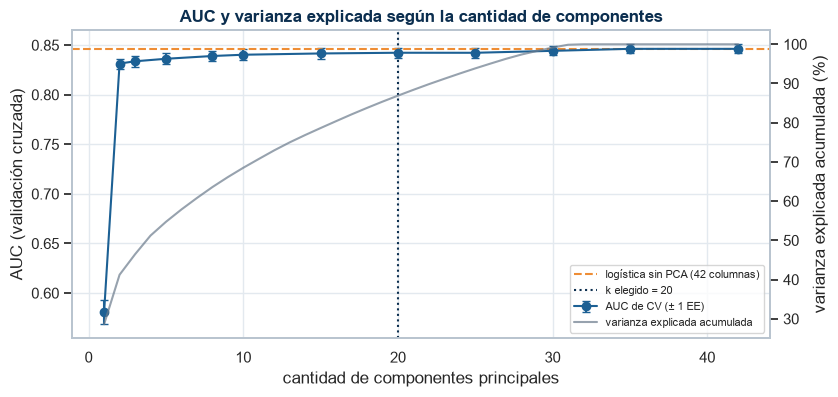

,C,AUC medio,EE
param_pca__n_components,,,
1,0.1000,0.5808,0.0123
2,10.0000,0.8314,0.0051
3,10.0000,0.8337,0.0053
5,10.0000,0.8362,0.0056
8,0.1000,0.8390,0.0052
10,10.0000,0.8403,0.0054
15,0.1000,0.8416,0.0054
20,0.1000,0.8423,0.0051
25,0.1000,0.8423,0.0049


In [36]:
fig, ax1 = plt.subplots(figsize=(9, 4))                     # figura con dos ejes
ax1.errorbar(por_k.index, por_k['AUC medio'], yerr=por_k['EE'], marker='o', color=AZUL_UTN, capsize=3,   # AUC medio ± 1 EE según k
             label='AUC de CV (± 1 EE)')                    # AUC según k
ax1.axhline(auc_por_fold['Logística'].mean(), color=NARANJA, ls='--', label='logística sin PCA (42 columnas)')   # referencia
ax1.axvline(k_elegido, color=AZUL_OSCURO, ls=':', label=f'k elegido = {k_elegido}')   # k elegido
ax1.set_xlabel('cantidad de componentes principales')       # eje x
ax1.set_ylabel('AUC (validación cruzada)')                  # eje y izquierdo
ax2 = ax1.twinx()                                           # segundo eje y
ax2.plot(range(1, len(var_acum) + 1), var_acum * 100, color=GRIS, alpha=0.7, label='varianza explicada acumulada')   # varianza
ax2.set_ylabel('varianza explicada acumulada (%)')          # eje y derecho
ax2.grid(False)                                             # sin grilla duplicada
lineas = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]   # leyendas de los dos ejes
etiquetas = ax1.get_legend_handles_labels()[1] + ax2.get_legend_handles_labels()[1]   # textos
ax1.legend(lineas, etiquetas, loc='lower right', fontsize=8)   # una sola leyenda
ax1.set_title('AUC y varianza explicada según la cantidad de componentes')   # título
guardar_figura('pca_componentes')                           # guardo el PNG
plt.show()                                                  # muestro la figura
por_k                                                       # muestro la tabla

Una sola componente casi no predice (AUC 0,58), aunque es la de más varianza; con dos, el AUC sube a 0,83, y después crece despacio hasta igualar a la logística original recién con 35 componentes. Con 20 componentes se conserva el 86,9% de la varianza.

La curva es tan plana entre 15 y 25 componentes que conviene mirar con más cifras dónde corta la regla. La celda siguiente solo imprime el límite y el AUC de 15 y 20 componentes con seis decimales; no cambia el `k` elegido.

In [37]:
for k_v in [15, 20]:                                        # los dos candidatos vecinos al límite
    print(f'k = {k_v}: AUC {por_k.loc[k_v, "AUC medio"]:.6f} | margen sobre el límite {por_k.loc[k_v, "AUC medio"] - limite_k:+.6f}')   # AUC y margen
print(f'Límite de la regla de 1 EE: {limite_k:.6f}')          # mejor AUC menos su EE

k = 15: AUC 0.841594 | margen sobre el límite -0.000040
k = 20: AUC 0.842314 | margen sobre el límite +0.000681
Límite de la regla de 1 EE: 0.841633


Con 15 componentes el AUC es 0,841594, apenas 0,00004 por debajo del límite de 0,841633; con 20 lo supera por 0,0007. La regla prefiere 20 sobre 15 por una diferencia en la quinta cifra decimal, mucho menor que el error estándar entre folds (0,005). La elección es frágil: con otra partición en folds podría quedar 15. Mantenemos `k = 20` porque la regla se fijó de antemano, y entre 15 y 20 componentes el AUC difiere en menos de una milésima.

> **Decisión ML12:** elegir la cantidad de componentes y `C` por validación cruzada, con la regla de un error estándar, y usar ese modelo como versión con PCA para volver a predecir.
>
> **Justificación:** la validación cruzada mide directamente lo que importa, el AUC, mientras que los criterios de varianza o del codo no miran el churn (James et al., 2023, secs. 6.3.1 y 12.2.4; Géron, 2022, cap. 8). La regla elige 20 componentes con `C = 0,1` (AUC 0,8423), el menor modelo dentro de un error estándar del mejor. Dos salvedades: la elección entre 15 y 20 componentes es frágil, y `C = 0,1` es el borde inferior de su grilla, así que una penalización más fuerte no quedó probada. Con un AUC tan plano en esa zona, ninguna de las dos cosas debería mover el resultado más de unas milésimas.

## 8.4 Qué representan las primeras componentes

Leemos los loadings de las tres primeras componentes del PCA ajustado con todo train. El loading de una columna es su peso en la combinación lineal que define la componente, así que las columnas con loadings grandes y del mismo signo se mueven juntas. Imprimimos las siete columnas de mayor peso absoluto en cada componente. El signo de cada componente es arbitrario, y como el PCA no vio el churn, la relación de cada componente con la baja la verificamos en el gráfico.

In [38]:
cargas = pd.DataFrame(pca_completo.components_[:3].T, index=nombres_cortos, columns=['PC1', 'PC2', 'PC3'])   # loadings
for pc in cargas.columns:                                   # para cada componente
    top = cargas[pc].reindex(cargas[pc].abs().sort_values(ascending=False).index)[:7]   # las 7 cargas más grandes
    print(f'{pc} ({pca_completo.explained_variance_ratio_[int(pc[2]) - 1]:.1%} de la varianza):',   # componente y su varianza
          ', '.join(f'{n} {v:+.2f}' for n, v in top.items()))   # muestro las cargas

PC1 (28.6% de la varianza): TotalCharges +0.55, tenure +0.46, MonthlyCharges +0.45, StreamingMovies_Yes +0.17, StreamingTV_Yes +0.17, DeviceProtection_Yes +0.16, OnlineBackup_No -0.16
PC2 (12.6% de la varianza): MonthlyCharges +0.53, tenure -0.49, InternetService_Fiber optic +0.26, Contract_Month-to-month +0.26, InternetService_No -0.21, PaymentMethod_Electronic check +0.18, Contract_Two year -0.18
PC3 (5.2% de la varianza): InternetService_DSL +0.50, OnlineSecurity_No -0.39, OnlineSecurity_Yes +0.32, InternetService_Fiber optic -0.28, TechSupport_Yes +0.27, OnlineBackup_No -0.23, InternetService_No -0.22


Proyectamos a cada cliente de train sobre las dos primeras componentes y lo coloreamos según si se fue. Si una componente separa a los que se van, los puntos naranjas deberían concentrarse hacia uno de sus extremos.

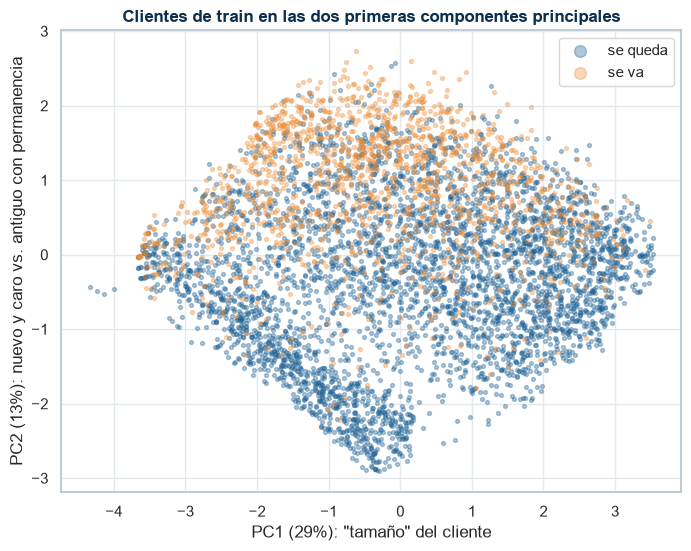

In [39]:
Z = pca_completo.transform(Z_prep)[:, :2]                   # cada cliente de train en el plano PC1-PC2
fig, ax = plt.subplots(figsize=(8, 6))                      # figura
for clase, etiqueta in [(0, 'se queda'), (1, 'se va')]:     # primero los que se quedan, encima los que se van
    m = y_train == clase                                    # clientes de esa clase
    ax.scatter(Z[m, 0], Z[m, 1], s=8, alpha=0.35, color=COLORES_CHURN[clase], label=etiqueta)   # puntos
ax.set_xlabel(f'PC1 ({pca_completo.explained_variance_ratio_[0]:.0%}): "tamaño" del cliente')   # eje x
ax.set_ylabel(f'PC2 ({pca_completo.explained_variance_ratio_[1]:.0%}): nuevo y caro vs. antiguo con permanencia')   # eje y
ax.set_title('Clientes de train en las dos primeras componentes principales')   # título
ax.legend(markerscale=3)                                    # leyenda
guardar_figura('pca_plano')                                 # guardo el PNG
plt.show()                                                  # muestro la figura

PC1 (28,6% de la varianza) reúne con el mismo signo a `TotalCharges`, `tenure` y `MonthlyCharges` y a los adicionales contratados: mide el "tamaño" del cliente y por eso no separa a los que se van, que hay grandes y chicos. PC2 (12,6%) opone `MonthlyCharges` alto, fibra, contrato mes a mes y cheque electrónico a `tenure` alta, contrato de dos años y sin internet. Es casi el perfil de riesgo del EDA, y en el plano los clientes que se van se concentran arriba. PC3 (5,2%) distingue DSL con seguridad y soporte de fibra sin ellos. Esto explica el salto del AUC entre una y dos componentes: la señal de churn está en PC2.

## 8.5 Nueva predicción con PCA

Con la versión elegida calculamos probabilidades fuera del fold, igual que en la sección 7.1, para comparar su AUC, su calibración y su costo con los de la logística sin PCA. Esperamos una pérdida chica de AUC y una probabilidad media todavía cercana a la tasa real.

In [40]:
modelo_pca = busqueda_pca.best_estimator_.set_params(pca__n_components=k_elegido, modelo__C=C_pca)   # k y C elegidos
modelo_pca.fit(X_train, y_train)                            # lo ajusto con todo train
prob_oof_pca = cross_val_predict(modelo_pca, X_train, y_train, cv=CV, method='predict_proba')[:, 1]   # fuera del fold
print(f'Versión con PCA: {k_elegido} componentes en lugar de {len(NOMBRES_COLS)} columnas')   # tamaño
print(f'AUC fuera del fold: {roc_auc_score(y_train, prob_oof_pca):.4f} (sin PCA: {roc_auc_score(y_train, prob_oof):.4f}) | '   # AUC con y sin PCA
      f'probabilidad media: {prob_oof_pca.mean():.4f} (tasa real {y_train.mean():.4f})')   # discriminación y calibración
print(f'Costo en train con umbral {UMBRAL_TEORICO:.3f}: con PCA {costo_total(y_train, prob_oof_pca, UMBRAL_TEORICO):,.0f} | '   # costo con PCA
      f'sin PCA {costo_total(y_train, prob_oof, UMBRAL_TEORICO):,.0f}')   # costo de cada versión

Versión con PCA: 20 componentes en lugar de 42 columnas
AUC fuera del fold: 0.8419 (sin PCA: 0.8459) | probabilidad media: 0.2652 (tasa real 0.2654)
Costo en train con umbral 0.134: con PCA 504,462 | sin PCA 502,341


La versión con PCA usa menos de la mitad de las columnas, pierde 4 milésimas de AUC (0,8419 contra 0,8459 fuera del fold) y cuesta algo más con el mismo umbral (504.462 contra 502.341). Sigue calibrada en promedio, de modo que el umbral teórico también vale para ella.

Repetimos ahora la comparación con Random Forest, que funciona de otro modo. Cada modelo usa los hiperparámetros elegidos para su entrada, así que para el Random Forest con PCA hacemos una nueva búsqueda con la grilla de la sección 6. Los hiperparámetros que sirven para 42 columnas casi binarias no tienen por qué servir para 20 componentes continuas.

In [41]:
rf_params = {k.replace('modelo__', ''): v for k, v in busquedas['Random Forest'].best_params_.items()}   # elegidos sin PCA
busqueda_rf_pca = GridSearchCV(Pipeline([('prep', PREP), ('pca', PCA(n_components=k_elegido, random_state=SEED)),   # preprocesamiento y PCA
                                         ('modelo', RandomForestClassifier(n_estimators=500, random_state=SEED, n_jobs=1))]),   # Random Forest de 500 árboles
                               {'modelo__min_samples_leaf': [5, 10, 20, 40], 'modelo__max_features': ['sqrt', 0.3]},   # grilla de la sección 6
                               cv=CV, scoring='roc_auc', n_jobs=-1)   # misma grilla de la sección 6, ahora con PCA
busqueda_rf_pca.fit(X_train, y_train)                       # nueva búsqueda para las componentes
rf_params_pca = {k.replace('modelo__', ''): v for k, v in busqueda_rf_pca.best_params_.items()}   # elegidos con PCA
print('Random Forest sin PCA:', rf_params, '| con PCA:', rf_params_pca)   # hiperparámetros de cada uno

Random Forest sin PCA: {'max_features': 'sqrt', 'min_samples_leaf': 20} | con PCA: {'max_features': 0.3, 'min_samples_leaf': 40}


Con los hiperparámetros de cada caso, evaluamos los cuatro pipelines (logística y Random Forest, con y sin PCA) en los folds comunes. Registramos el AUC de validación y de entrenamiento, su brecha y el tiempo medio de ajuste. Medimos el tiempo porque la eficiencia es uno de los motivos habituales para reducir la dimensión (VanderPlas, 2016, cap. 5). Para que los tiempos sean comparables, esta evaluación usa un solo núcleo.

In [42]:
filas = []                                                  # una fila por combinación
for nombre_modelo, crear in [('Logística', lambda pca: LogisticRegression(C=C_pca if pca else C_LOG, max_iter=2000)),   # su C en cada caso
                             ('Random Forest', lambda pca: RandomForestClassifier(n_estimators=500, random_state=SEED, n_jobs=1,   # Random Forest
                                                                                  **(rf_params_pca if pca else rf_params)))]:   # sus hiperparámetros
    for con_pca in [False, True]:                           # sin y con PCA
        pasos = [('prep', PREP)] + ([('pca', PCA(n_components=k_elegido, random_state=SEED))] if con_pca else [])   # PCA opcional
        r = cross_validate(Pipeline(pasos + [('modelo', crear(con_pca))]), X_train, y_train, cv=CV,   # pipeline con o sin PCA
                           scoring='roc_auc', return_train_score=True)   # mismos folds, en un núcleo para comparar tiempos
        filas.append({'modelo': nombre_modelo, 'entrada': f'PCA ({k_elegido} comp.)' if con_pca else '42 columnas',   # modelo y entrada
                      'AUC validación': r['test_score'].mean(), 'AUC train': r['train_score'].mean(),   # AUC de validación y de train
                      'segundos por ajuste': r['fit_time'].mean()})   # resultado
pca_vs_modelos = pd.DataFrame(filas).set_index(['modelo', 'entrada'])   # tabla
pca_vs_modelos['brecha train - valid.'] = pca_vs_modelos['AUC train'] - pca_vs_modelos['AUC validación']   # sobreajuste
pca_vs_modelos.round(4)                                     # muestro la tabla

AUC validación  AUC train  segundos por ajuste  \
modelo        entrada                                                          
Logística     42 columnas             0.8463     0.8511               0.3775   
              PCA (20 comp.)          0.8423     0.8450               0.3690   
Random Forest 42 columnas             0.8437     0.8801               0.7617   
              PCA (20 comp.)          0.8398     0.8859               2.9986   

                              brecha train - valid.  
modelo        entrada                                
Logística     42 columnas                    0.0048  
              PCA (20 comp.)                 0.0027  
Random Forest 42 columnas                    0.0364  
              PCA (20 comp.)                 0.0461

Con Random Forest la pérdida de AUC es parecida, pero el modelo necesita otros hiperparámetros para no sobreajustar: hojas de 40 clientes y el 30% de las variables por corte. Los dos valores están en el borde de la grilla, de modo que hojas más grandes podrían reducir algo la brecha; no lo probamos para mantener la misma grilla de la sección 6. Aun así, su brecha entre train y validación sube de 0,036 a 0,046, mientras la de la logística baja. Un árbol corta por una variable a la vez, y con las variables originales esos cortes ("¿mes a mes?") separan bien. Las componentes, en cambio, mezclan todas las variables, y reproducir un corte así requiere muchos cortes poco informativos. La logística, en cambio, puede reconstruir cualquier combinación lineal dentro del espacio de las 20 componentes, y solo pierde lo que queda afuera. Tampoco hay ganancia de tiempo: la logística entrena en centésimas de segundo con o sin PCA, y Random Forest tarda más con PCA, porque cada componente continua ofrece muchos más cortes posibles que una dummy.

El PCA no mejora acá porque el problema no tenía exceso de dimensiones: hay más de 130 clientes por columna, las variables están poco correlacionadas y la logística regularizada casi no sobreajusta. Su aporte es descriptivo, porque PC2 recupera por sí sola el perfil de riesgo del EDA.

# 9. Evaluación final en test

Con todo decidido, usamos el test una sola vez para medir tres modelos fijados de antemano. Son la logística final (ML9) con el umbral 0,134 (ML10), la versión con PCA (ML12) con el mismo umbral, que es la nueva predicción que pide la consigna, y el ensamble como contraste. Los intervalos del 95% salen de 1.000 remuestras bootstrap de los 1.409 clientes de test, y las diferencias entre modelos se calculan sobre las mismas remuestras (James et al., 2023, sec. 5.2; Efron y Tibshirani, 1993).

## 9.1 Probabilidades en test e intervalos bootstrap

Los tres modelos ya están ajustados con todo train; el ensamble lo ajustamos acá. Calculamos sus probabilidades para los clientes de test y preparamos el bootstrap. Una remuestra bootstrap sortea 1.409 clientes de test con reposición, de modo que algunos aparecen más de una vez y otros ninguna. Repetimos el sorteo 1.000 veces y calculamos la métrica en cada remuestra; los percentiles 2,5 y 97,5 de esos valores forman el intervalo del 95%. Generamos las remuestras una sola vez y las reutilizamos para todas las métricas y todos los modelos. Esta celda no imprime nada.

In [43]:
modelos_test = {'Logística (final)': mejor_logistica, f'Logística + PCA ({k_elegido} comp.)': modelo_pca,   # final y versión con PCA
                'Ensamble (contraste)': ensamble.fit(X_train, y_train)}   # los tres modelos, ajustados con todo train
prob_test = {nombre: m.predict_proba(X_test)[:, 1] for nombre, m in modelos_test.items()}   # probabilidades en test

rng = np.random.default_rng(SEED)                           # generador con semilla
remuestras = rng.integers(0, len(y_test), size=(1000, len(y_test)))   # 1.000 remuestras bootstrap de test


def ic_bootstrap(metrica):   # intervalo del 95% por percentiles
    # aplica la métrica a cada remuestra y devuelve los percentiles 2,5 y 97,5
    valores = np.array([metrica(idx) for idx in remuestras])   # la métrica en cada remuestra
    return np.percentile(valores, [2.5, 97.5])              # intervalo del 95%

## 9.2 Métricas en test

Para cada modelo calculamos el AUC con su intervalo y, con el umbral de 0,134, las métricas de la decisión. El recall es la parte de las bajas a las que llega la oferta, y la precisión, la parte de las ofertas que va a clientes que se iban. La especificidad es la parte de los que se quedan a los que no se contacta. La accuracy va solo como contexto, porque con esta matriz de costos no es lo que queremos maximizar. Agregamos la cantidad de ofertas, el costo y la probabilidad media, que controla la calibración en clientes nuevos.

Imprimimos también el error estándar del recall, $\sqrt{\text{rec}\,(1 - \text{rec}) / n}$ con $n$ igual a la cantidad de bajas en test, para saber cuánta precisión podemos atribuirle. Esperamos un AUC cercano al de la validación cruzada.

In [44]:
filas = []                                                  # una fila por modelo
for nombre, p in prob_test.items():                         # recorro los modelos
    ofrece = p >= UMBRAL_TEORICO                            # decisión con el umbral por costos
    vp = (ofrece & (y_test == 1)).sum()                     # se iban y les ofrecimos
    fila = {'AUC': roc_auc_score(y_test, p)}                # AUC en test
    fila['IC 95% AUC'] = ic_bootstrap(lambda i: roc_auc_score(y_test[i], p[i])).round(3)   # su intervalo
    fila['recall'] = vp / (y_test == 1).sum()               # de los que se van, a cuántos alcanzamos
    fila['precisión'] = vp / ofrece.sum()                   # de las ofertas, cuántas fueron a quien se iba
    fila['especificidad'] = (~ofrece & (y_test == 0)).sum() / (y_test == 0).sum()   # de los que se quedan, a cuántos no contactamos
    fila['accuracy'] = (ofrece == (y_test == 1)).mean()     # solo como contexto
    fila['ofertas'] = int(ofrece.sum())                     # cuántos clientes contactamos
    fila['costo'] = costo_total(y_test, p, UMBRAL_TEORICO)  # costo con la matriz de la decisión 18
    fila['prob. media'] = p.mean()                          # control de calibración
    filas.append(pd.Series(fila, name=nombre))              # guardo la fila
resultados_test = pd.DataFrame(filas)                       # tabla de resultados
rec = resultados_test.loc['Logística (final)', 'recall']    # recall del modelo final
print(f'Tasa real de churn en test: {y_test.mean():.4f} | churners en test: {(y_test == 1).sum()} | '   # tasa y bajas en test
      f'error estándar del recall final: {np.sqrt(rec * (1 - rec) / (y_test == 1).sum()) * 100:.1f} puntos')   # tamaño de la muestra
resultados_test                                             # muestro la tabla

Tasa real de churn en test: 0.2654 | churners en test: 374 | error estándar del recall final: 1.4 puntos


,AUC,IC 95% AUC,recall,precisión,especificidad,accuracy,ofertas,costo,prob. media
Logística (final),0.8437,"[0.824, 0.867]",0.9171,0.4250,0.5517,0.6487,807,124647.0000,0.2691
Logística + PCA (20 comp.),0.8380,"[0.818, 0.86]",0.9225,0.4192,0.5382,0.6402,823,124773.0000,0.2696
Ensamble (contraste),0.8435,"[0.823, 0.866]",0.9144,0.4264,0.5556,0.6508,802,124944.0000,0.2680


El AUC del modelo final en test es 0,8437 (IC 95%: 0,824 a 0,867), cerca del 0,8463 de la validación cruzada: la estimación de la CV era honesta. Con el umbral 0,134, el modelo contacta a 807 clientes y alcanza al 91,7% de los que se van, con una precisión de 0,425 y una accuracy de 0,649. La accuracy baja es aceptable bajo esta matriz de costos, porque cada error del modelo es una oferta de 120, mucho más barata que un cliente perdido. Con 374 bajas en test, el recall tiene un error estándar de 1,4 puntos. La probabilidad media predicha (0,269) se mantiene cerca de la tasa real (0,265).

La probabilidad media es un control global. Para ver la calibración en clientes nuevos con más detalle, repetimos en test la tabla por deciles de la sección 7.2 para el modelo final y calculamos el puntaje de Brier de los tres modelos. El Brier es el error cuadrático medio entre la probabilidad y lo que pasó, $\frac{1}{n}\sum_i (p_i - y_i)^2$, y cuanto más bajo, mejor (Brier, 1950). Como referencia agregamos el Brier de asignar a todos la tasa de bajas de train.

Con 1.409 clientes, cada decil de test tiene unos 141, así que el error estándar de la tasa de un decil calibrado llega a unos 4 puntos. Por eso agregamos esa columna y contamos cuántos deciles se apartan de su probabilidad media en más de dos errores estándar. Es una celda de solo lectura: no cambia el modelo ni el umbral.

In [45]:
brier = pd.Series({nombre: np.mean((p - y_test) ** 2) for nombre, p in prob_test.items()}, name='Brier en test')   # error cuadrático medio
brier['referencia: tasa de train para todos'] = np.mean((y_train.mean() - y_test) ** 2)   # sin modelo
print(brier.round(4).to_string() + '\n')                    # muestro el Brier
p_fin_t = prob_test['Logística (final)']                    # probabilidades del modelo final en test
dec_t = pd.qcut(p_fin_t, 10, labels=False)                  # decil de probabilidad en test
calib_test = pd.DataFrame({'prob. predicha media': pd.Series(p_fin_t).groupby(dec_t).mean(),   # probabilidad media por decil
                           'tasa real de churn': pd.Series(y_test).groupby(dec_t).mean(),     # tasa real por decil
                           'clientes': pd.Series(y_test).groupby(dec_t).size()})              # clientes por decil
calib_test.index.name = 'decil'                             # nombre de las filas
calib_test['diferencia'] = calib_test['tasa real de churn'] - calib_test['prob. predicha media']   # tasa real menos probabilidad
calib_test['EE de la tasa'] = np.sqrt(calib_test['prob. predicha media'] * (1 - calib_test['prob. predicha media']) / calib_test['clientes'])   # ruido esperado si está calibrado
print('Deciles que se apartan más de 2 EE:', int((calib_test['diferencia'].abs() > 2 * calib_test['EE de la tasa']).sum()), 'de 10')   # control
calib_test                                                  # muestro la tabla

Logística (final)                      0.1362
Logística + PCA (20 comp.)             0.1384
Ensamble (contraste)                   0.1364
referencia: tasa de train para todos   0.1950

Deciles que se apartan más de 2 EE: 0 de 10


,prob. predicha media,tasa real de churn,clientes,diferencia,EE de la tasa
decil,,,,,
0,0.0094,0.0071,141,-0.0023,0.0081
1,0.0244,0.0284,141,0.0040,0.0130
2,0.0473,0.0496,141,0.0023,0.0179
3,0.0899,0.0922,141,0.0023,0.0241
4,0.1470,0.1844,141,0.0374,0.0298
5,0.2286,0.1929,140,-0.0357,0.0355
6,0.3298,0.3262,141,-0.0036,0.0396
7,0.4517,0.4681,141,0.0164,0.0419
8,0.5903,0.5603,141,-0.0300,0.0414


En test, el puntaje de Brier del modelo final es 0,136, contra 0,195 de asignar a todos la tasa de train. El ensamble queda prácticamente igual (0,136) y la versión con PCA algo peor (0,138). Ningún decil se aparta de su probabilidad media en más de dos errores estándar. Cerca del umbral, el decil 4 predice 14,7% y se va el 18,4%, una diferencia de 3,7 puntos, poco más de un error estándar. Si ese desvío fuera real, el modelo subestimaría algo el riesgo de esos clientes, pero la mayoría ya supera 0,134 y recibe la oferta. La calibración que vimos en train se sostiene en clientes nuevos, dentro de lo que permite medir una muestra de 1.409.

## 9.3 Diferencias entre modelos y ahorro

Calculamos la diferencia de AUC de la versión con PCA y del ensamble contra el modelo final, con un intervalo bootstrap pareado: en cada remuestra, los dos modelos se miden sobre los mismos clientes. Si el intervalo incluye el cero, la diferencia no se distingue del ruido de muestreo. Con el mismo procedimiento calculamos el intervalo del ahorro del modelo final frente a ofrecer a todos.

In [46]:
p_final = prob_test['Logística (final)']                    # probabilidades del modelo final
for nombre in list(prob_test)[1:]:                          # diferencias contra el modelo final, bootstrap pareado
    p_otro = prob_test[nombre]                              # probabilidades del otro modelo
    dif = roc_auc_score(y_test, p_otro) - roc_auc_score(y_test, p_final)   # diferencia de AUC en test
    ic = ic_bootstrap(lambda i: roc_auc_score(y_test[i], p_otro[i]) - roc_auc_score(y_test[i], p_final[i]))   # mismas remuestras
    print(f'{nombre} - final: AUC {dif:+.4f}, IC 95% [{ic[0]:+.4f}, {ic[1]:+.4f}]')   # resultado

ic_costo = ic_bootstrap(lambda i: 1 - costo_total(y_test[i], p_final[i], UMBRAL_TEORICO) / costo_total(y_test[i], p_final[i], 0.0)) * 100   # intervalo del ahorro
print(f'Ahorro del modelo frente a ofrecer a todos: IC 95% [{ic_costo[0]:.1f}%, {ic_costo[1]:.1f}%]')   # resultado

Logística + PCA (20 comp.) - final: AUC -0.0056, IC 95% [-0.0107, -0.0007]


Ensamble (contraste) - final: AUC -0.0001, IC 95% [-0.0027, +0.0028]
Ahorro del modelo frente a ofrecer a todos: IC 95% [20.5%, 32.1%]


El ensamble empata en test: la diferencia es de -0,0001, con un intervalo que incluye el cero. La versión con PCA pierde 0,0056 de AUC con un intervalo que no incluye el cero, en línea con lo que mostró la validación cruzada. El ahorro del modelo final frente a ofrecer a todos tiene un intervalo de 20,5% a 32,1%.

## 9.4 Curva ROC y matriz de confusión

La curva ROC muestra, para cada umbral posible, la tasa de verdaderos positivos (recall) contra la de falsos positivos (1 menos la especificidad). El AUC es el área bajo esa curva, y la diagonal corresponde a ordenar al azar. Marcamos el punto que corresponde al umbral de 0,134. A la derecha, la matriz de confusión del modelo final cuenta a los clientes de test según lo que decidió el modelo y lo que pasó.

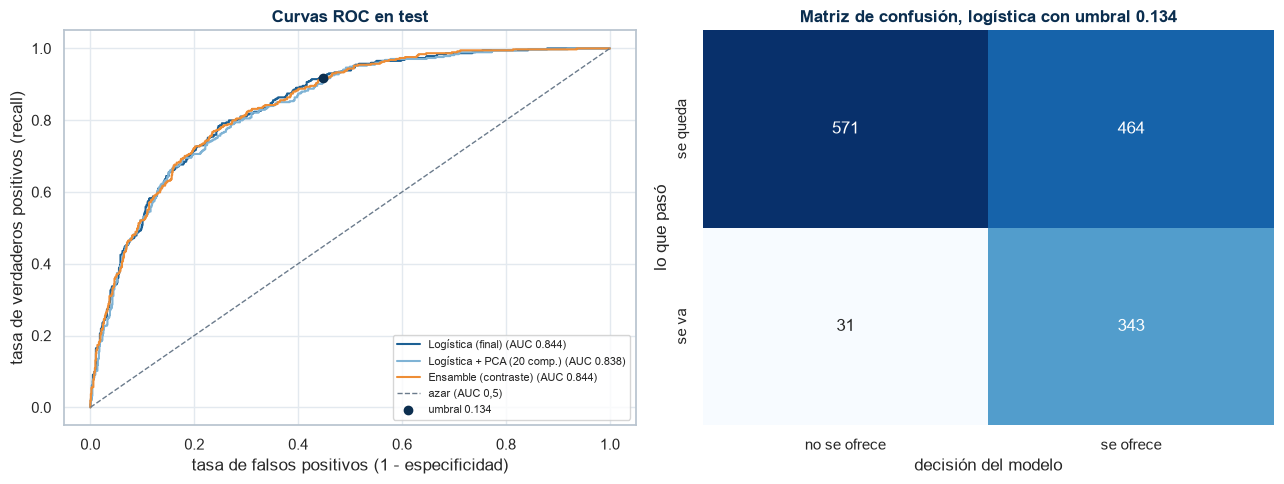

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))             # dos paneles
for (nombre, p), color in zip(prob_test.items(), [AZUL_UTN, CELESTE, NARANJA]):   # curva ROC de cada modelo
    fpr, tpr, _ = roc_curve(y_test, p)                      # tasas de falsos y verdaderos positivos
    axes[0].plot(fpr, tpr, color=color, label=f'{nombre} (AUC {roc_auc_score(y_test, p):.3f})')   # curva
axes[0].plot([0, 1], [0, 1], color=GRIS, ls='--', lw=1, label='azar (AUC 0,5)')   # diagonal
fpr_u = ((p_final >= UMBRAL_TEORICO) & (y_test == 0)).sum() / (y_test == 0).sum()   # punto del umbral elegido
tpr_u = ((p_final >= UMBRAL_TEORICO) & (y_test == 1)).sum() / (y_test == 1).sum()   # recall en ese punto
axes[0].scatter([fpr_u], [tpr_u], color=AZUL_OSCURO, zorder=3, label=f'umbral {UMBRAL_TEORICO:.3f}')   # marco el umbral
axes[0].set_xlabel('tasa de falsos positivos (1 - especificidad)')   # eje x
axes[0].set_ylabel('tasa de verdaderos positivos (recall)')  # eje y
axes[0].set_title('Curvas ROC en test')                      # título
axes[0].legend(fontsize=8, loc='lower right')                # leyenda
cm = confusion_matrix(y_test, (p_final >= UMBRAL_TEORICO).astype(int), labels=[0, 1])   # matriz de confusión del modelo final
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[1],   # mapa de calor con los conteos
            xticklabels=['no se ofrece', 'se ofrece'], yticklabels=['se queda', 'se va'])   # con rótulos explícitos
axes[1].set_xlabel('decisión del modelo')                    # eje x
axes[1].set_ylabel('lo que pasó')                            # eje y
axes[1].set_title(f'Matriz de confusión, logística con umbral {UMBRAL_TEORICO:.3f}')   # título
plt.tight_layout()                                          # acomodo
guardar_figura('test_roc_confusion')                        # guardo el PNG
plt.show()                                                  # muestro la figura

Las tres curvas casi se superponen. El punto del umbral queda en la zona de recall alto, donde el modelo acepta muchos falsos positivos a cambio de perder pocas bajas, que es lo que piden los costos. La matriz lo muestra en clientes: quedan sin oferta 31 de las 374 bajas, y a cambio se hacen 464 ofertas a clientes que se iban a quedar.

## 9.5 Costo en test frente a las estrategias sin modelo

Por último, calculamos en test el costo de las mismas estrategias de la sección 7 y el ahorro del modelo frente a ofrecer a todos. Para ver qué cambia el umbral, comparamos el mismo modelo con 0,5 y con 0,134 en una tabla con un umbral por fila: recall, precisión, ofertas y costo. Esperamos que, igual que en train, el umbral de 0,5 cueste más que ofrecer a todos.

In [48]:
estrategias_test = pd.Series({                              # costos de cada estrategia en test
    'nadie (no ofrecer)': costo_total(y_test, p_final, 1.01),   # sin campaña
    'a todos': costo_total(y_test, p_final, 0.0),           # campaña masiva
    'logística, umbral 0,5': costo_total(y_test, p_final, 0.5),   # umbral por defecto
    f'logística, umbral {UMBRAL_TEORICO:.3f}': costo_total(y_test, p_final, UMBRAL_TEORICO),   # el modelo final
}, name='costo total en test')                              # tabla de costos
estrategias_test['ahorro vs. a todos (%)'] = (1 - estrategias_test.iloc[3] / estrategias_test['a todos']) * 100   # ahorro del modelo
umbrales_test = pd.DataFrame([{                             # el mismo modelo con los dos umbrales, un umbral por fila
    'umbral': f'{u:.3f}',                                   # rótulo de la fila
    'recall': ((p_final >= u) & (y_test == 1)).sum() / (y_test == 1).sum(),   # bajas alcanzadas
    'precisión': y_test[p_final >= u].mean(),               # bajas entre los contactados
    'ofertas': int((p_final >= u).sum()),                   # clientes contactados (entero)
    'costo': int(costo_total(y_test, p_final, u))} for u in [0.5, UMBRAL_TEORICO]]).set_index('umbral')   # costo total (entero)
print(umbrales_test.to_string(float_format='{:.3f}'.format) + '\n')   # recall y precisión con 3 decimales; ofertas y costo enteros
estrategias_test.round(1).to_frame()                        # muestro la tabla

        recall  precisión  ofertas   costo
umbral                                    
0.500    0.524      0.651      301  195786
0.134    0.917      0.425      807  124647



,costo total en test
nadie (no ofrecer),335478.0000
a todos,169080.0000
"logística, umbral 0,5",195786.0000
"logística, umbral 0.134",124647.0000
ahorro vs. a todos (%),26.3000


En costo, el modelo (124.647) supera a no ofrecer (335.478), a ofrecer a todos (169.080) y al umbral 0,5 (195.786), que vuelve a quedar peor que ofrecer a todos. Con 0,5, el mismo modelo hace solo 301 ofertas y alcanza al 52,4% de las bajas, contra el 91,7% con 0,134. El ahorro frente a ofrecer a todos es del 26,3%.

En test, el ensamble cuesta algo más que la logística (124.944 contra 124.647) y la versión con PCA casi lo mismo (124.773), porque con un umbral tan bajo los tres modelos contactan a casi los mismos clientes. En validación, en cambio, el ensamble costaba un 1,3% menos (sección 7.4). Para saber si alguna de estas diferencias se distingue del ruido de muestreo, calculamos su intervalo bootstrap pareado con las mismas 1.000 remuestras de la sección 9.1, reutilizando `ic_bootstrap`. Es una celda de solo lectura.

In [49]:
costo_final = costo_total(y_test, p_final, UMBRAL_TEORICO)  # costo del modelo final en test
for nombre in list(prob_test)[1:]:                          # versión con PCA y ensamble
    p_otro = prob_test[nombre]                              # probabilidades del otro modelo
    d = costo_total(y_test, p_otro, UMBRAL_TEORICO) - costo_final   # diferencia de costo en test (positiva = cuesta más)
    ic_d = ic_bootstrap(lambda i: costo_total(y_test[i], p_otro[i], UMBRAL_TEORICO) - costo_total(y_test[i], p_final[i], UMBRAL_TEORICO))   # mismas remuestras
    print(f'{nombre} - final: costo {d:+,.0f} ({d / costo_final * 100:+.2f}%), '   # diferencia absoluta y relativa
          f'IC 95% [{ic_d[0]:+,.0f}, {ic_d[1]:+,.0f}] ({ic_d[0] / costo_final * 100:+.1f}% a {ic_d[1] / costo_final * 100:+.1f}%)')   # intervalo

Logística + PCA (20 comp.) - final: costo +126 (+0.10%), IC 95% [-6,155, +6,759] (-4.9% a +5.4%)
Ensamble (contraste) - final: costo +297 (+0.24%), IC 95% [-4,012, +4,656] (-3.2% a +3.7%)


Las dos diferencias de costo son chicas frente a su incertidumbre. El ensamble cuesta 297 más que la logística (+0,24%), con un intervalo de -4.012 a +4.656 que incluye el cero. La versión con PCA cuesta 126 más, con un intervalo de -6.155 a +6.759. Con 1.409 clientes, el test no distingue el costo de los tres modelos.

Por eso no afirmamos que elegir el modelo simple no tuvo costo, sino que no encontramos evidencia de que lo tuviera. El 1,3% de ahorro que el ensamble mostraba en validación cae dentro de su intervalo (-3,2% a +3,7%), así que el test tampoco lo descarta. La elección de la logística se apoya en la regla de la sección 3 y en la interpretabilidad, no en una ventaja de costo demostrada.

> **Decisión ML13:** informar el resultado en test de los tres modelos fijados de antemano, con intervalos bootstrap del 95%, la matriz de confusión y el costo frente a las estrategias sin modelo, sin volver atrás sobre ninguna decisión.
>
> **Justificación:** usamos el test solo para medir, y ningún resultado suyo nos hizo cambiar una decisión. Evaluar un conjunto cerrado de modelos evita quedarse con el que salió mejor por azar, y los intervalos muestran qué parte de cada diferencia es ruido de muestreo (Géron, 2022, cap. 2). El bootstrap pareado compara los modelos sobre los mismos clientes.

# 10. Interpretación y negocio

Interpretamos el modelo final por tres caminos: los coeficientes de la logística, convertidos en odds ratios; perfiles de clientes hipotéticos; y la importancia por permutación. Cerramos con la traducción del resultado a clientes y facturación.

## 10.1 Coeficientes de las numéricas

Las tres numéricas no las leemos por separado. Para mostrar por qué, comparamos sus coeficientes en el modelo final y en el mismo modelo sin `log1p`, ajustados con todo train y el mismo `C`. Como las numéricas están estandarizadas, cada coeficiente es el cambio en el logaritmo de las odds por un desvío estándar de la variable. Medimos también cuánto cambian las predicciones entre los dos modelos. Si los coeficientes cambian mucho y las predicciones poco, los coeficientes individuales no son confiables.

In [50]:
coefs = pd.Series(mejor_logistica.named_steps['modelo'].coef_[0], index=nombres_cortos)   # coeficientes por columna
sin_log = logistica(armar_preprocesador(excluir=EXCLUIR, log1p_total=False), C=C_LOG).fit(X_train, y_train)   # mismo modelo sin log1p
coefs_sin_log = pd.Series(sin_log.named_steps['modelo'].coef_[0],   # coeficientes del modelo sin log1p
                          index=[n.split('__')[1] for n in sin_log.named_steps['prep'].get_feature_names_out()])   # sus coeficientes
p_con, p_sin = mejor_logistica.predict_proba(X_train)[:, 1], sin_log.predict_proba(X_train)[:, 1]   # probabilidades de los dos modelos
print(f'Correlación entre las probabilidades de los dos modelos: {np.corrcoef(p_con, p_sin)[0, 1]:.2f} | '   # correlación de probabilidades
      f'diferencia media: {np.abs(p_con - p_sin).mean() * 100:.1f} puntos | '   # diferencia media en puntos
      f'clientes que cambian de decisión con el umbral {UMBRAL_TEORICO:.3f}: '   # clientes que cambian de decisión
      f'{((p_con >= UMBRAL_TEORICO) != (p_sin >= UMBRAL_TEORICO)).mean():.1%}')   # cuánto cambian las predicciones
pd.DataFrame({'con log1p (modelo final)': coefs[COLS_NUM], 'sin log1p': coefs_sin_log[COLS_NUM]}).round(2)   # coeficientes de las numéricas

Correlación entre las probabilidades de los dos modelos: 0.98 | diferencia media: 3.1 puntos | clientes que cambian de decisión con el umbral 0.134: 4.0%


,con log1p (modelo final),sin log1p
tenure,-0.3500,-1.1500
MonthlyCharges,0.2600,0.2500
TotalCharges,-0.7000,0.3000


En el modelo final, más antigüedad y más facturación acumulada van con menos riesgo y un cargo mensual más alto con más. Sin `log1p`, el coeficiente de `TotalCharges` cambia de signo (de -0,70 a +0,30), aunque el EDA mostró que los que se van acumularon menos, y el de `tenure` pasa de -0,35 a -1,15. Las predicciones cambian mucho menos que los coeficientes. La correlación entre las probabilidades de los dos modelos es 0,98, difieren en 3,1 puntos en promedio y solo el 4,0% de los clientes cambia de decisión, aunque el AUC baja 0,0045 (ML5). Como `TotalCharges` es aproximadamente `tenure × MonthlyCharges`, el modelo reparte el efecto de la antigüedad entre las tres variables de distintas formas según cómo entra cada una. Es el efecto de la colinealidad: afecta poco a la predicción y vuelve inestable cada coeficiente por separado (James et al., 2023, sec. 3.3.3). Por eso las numéricas las interpretamos con perfiles de cliente y los odds ratios siguientes son solo de las categóricas.

## 10.2 Odds ratios de las categóricas

Las odds de baja son $p / (1 - p)$: con una probabilidad de 0,5 valen 1, y con 0,8 valen 4. En una logística, $e^{\beta}$ es un odds ratio: el factor por el que se multiplican las odds cuando la dummy pasa de 0 a 1 con todo lo demás fijo (James et al., 2023, sec. 4.3.3). Con "Desconocido" y `drop='if_binary'`, la mayoría de las variables conserva todas sus categorías como columnas, y sus coeficientes no tienen una categoría de referencia propia. Por eso comparamos dentro de cada variable con $e^{\beta_A - \beta_B}$. Como referencia tomamos la categoría de menor riesgo esperado según el EDA: contrato de dos años, DSL y transferencia automática; en las variables de tipo sí o no, la referencia es "No".

Los coeficientes salen de la logística final, que tiene una penalización L2 suave (`C = 1`, el valor que eligió la búsqueda de la sección 6). La L2 achica los coeficientes hacia cero, de modo que estos odds ratios son algo conservadores. Un odds ratio mayor que 1 indica más riesgo que la referencia, y uno menor que 1, menos.

In [51]:
print(f'Odds ratios de la logística final (penalización L2, C = {C_LOG})')   # de qué modelo salen
REFERENCIAS = {'Contract': 'Two year', 'InternetService': 'DSL', 'PaymentMethod': 'Bank transfer (automatic)'}   # referencia por variable
filas = []                                                  # una fila por categoría
for var in [c for c in COLS_CAT if c not in EXCLUIR]:       # recorro las categóricas usadas
    cols = [n for n in coefs.index if n.startswith(var + '_')]   # columnas de esa variable
    if len(cols) == 1:                                      # binaria con una sola columna (la otra es la referencia)
        filas.append({'variable': var, 'categoría': cols[0][len(var) + 1:], 'referencia': 'No',   # if_binary descarta la primera en orden alfabético
                      'odds ratio': np.exp(coefs[cols[0]])})   # exp(β)
        continue                                            # paso a la siguiente variable
    ref = REFERENCIAS.get(var, 'No')                        # referencia elegida (No para las de Yes/No)
    for col in cols:                                        # cada categoría contra la referencia
        cat = col[len(var) + 1:]                            # nombre de la categoría
        if cat != ref:                                      # la referencia no se compara consigo misma
            filas.append({'variable': var, 'categoría': cat, 'referencia': ref,   # variable, categoría y referencia
                          'odds ratio': np.exp(coefs[col] - coefs[f'{var}_{ref}'])})   # exp(βA - βB)
odds_ratios = pd.DataFrame(filas).sort_values('odds ratio', ascending=False).reset_index(drop=True)   # de más a menos riesgo
odds_ratios                                                 # muestro la tabla

Odds ratios de la logística final (penalización L2, C = 1)


,variable,categoría,referencia,odds ratio
0,Contract,Month-to-month,Two year,3.7820
1,Contract,Desconocido,Two year,3.0688
2,InternetService,Fiber optic,DSL,2.5259
3,Contract,One year,Two year,2.0426
4,InternetService,Desconocido,DSL,1.8902
5,MultipleLines,No phone service,No,1.8044
6,MultipleLines,Desconocido,No,1.7620
7,PaperlessBilling,Yes,No,1.6316
8,MultipleLines,Yes,No,1.5831
9,PaperlessBilling,Desconocido,No,1.5173


Un odds ratio sin intervalo no dice cuánto podría cambiar con otra muestra de clientes. Para estimarlo usamos bootstrap sobre train (Efron y Tibshirani, 1993): sorteamos 5.634 clientes con reposición, reajustamos la logística final con el mismo preprocesamiento y el mismo `C`, y recalculamos cada odds ratio. Repetimos 200 veces con la semilla del trabajo y tomamos los percentiles 2,5 y 97,5.

Cada reajuste aprende de nuevo medianas, categorías y escalas dentro de su remuestra, como el pipeline original. El generador es propio de esta celda, así que no altera las remuestras de test ni ningún resultado anterior. Esperamos intervalos que excluyan el 1 en el contrato, la fibra y el cheque electrónico, y más anchos en las categorías chicas.

In [52]:
inicio = time.time()                                        # para medir el tiempo
rng_or = np.random.default_rng(SEED)                        # generador propio: no toca las remuestras de test
coefs_boot = []                                             # coeficientes de cada reajuste
for _ in range(200):                                        # 200 remuestras bootstrap de train
    idx = rng_or.integers(0, len(y_train), size=len(y_train))   # clientes sorteados con reposición
    m_b = logistica(armar_preprocesador(excluir=EXCLUIR), C=C_LOG).fit(X_train.iloc[idx], y_train[idx])   # mismo preprocesamiento y C
    nombres_b = [n.split('__')[1] for n in m_b.named_steps['prep'].get_feature_names_out()]   # columnas de esta remuestra
    coefs_boot.append(pd.Series(m_b.named_steps['modelo'].coef_[0], index=nombres_b))   # coeficientes por nombre de columna
coefs_boot = pd.DataFrame(coefs_boot)                       # una fila por remuestra
verificar(list(coefs_boot.columns) == list(coefs.index) and not coefs_boot.isna().any().any(),   # mismas columnas, sin huecos
          'las 200 remuestras generan las mismas 42 columnas')   # ninguna categoría desapareció en una remuestra


def log_or_boot(fila):   # log odds ratio de una fila de la tabla en cada remuestra
    # β_A - β_B si la referencia tiene columna propia; β_A si es la categoría descartada por if_binary
    col, col_ref = f"{fila['variable']}_{fila['categoría']}", f"{fila['variable']}_{fila['referencia']}"   # columnas de la categoría y la referencia
    return coefs_boot[col] - (coefs_boot[col_ref] if col_ref in coefs_boot else 0)   # diferencia de coeficientes


limites = np.array([np.exp(np.percentile(log_or_boot(f), [2.5, 97.5])) for _, f in odds_ratios.iterrows()])   # percentiles en escala de odds
odds_ratios_ic = odds_ratios.assign(**{'IC 95% inf.': limites[:, 0], 'IC 95% sup.': limites[:, 1]})   # tabla nueva; odds_ratios no cambia
odds_ratios_ic['¿incluye el 1?'] = np.where((limites[:, 0] < 1) & (limites[:, 1] > 1), 'sí', 'no')   # efecto distinguible o no
print(f'{len(coefs_boot)} reajustes en {time.time() - inicio:.0f} s')   # tiempo de cómputo
odds_ratios_ic.round(2)                                     # muestro la tabla

OK - las 200 remuestras generan las mismas 42 columnas
200 reajustes en 88 s


,variable,categoría,referencia,odds ratio,IC 95% inf.,IC 95% sup.,¿incluye el 1?
0,Contract,Month-to-month,Two year,3.7800,2.8300,5.4800,no
1,Contract,Desconocido,Two year,3.0700,2.2900,4.7000,no
2,InternetService,Fiber optic,DSL,2.5300,1.7400,3.3700,no
3,Contract,One year,Two year,2.0400,1.4500,3.1600,no
4,InternetService,Desconocido,DSL,1.8900,1.3500,2.5300,no
5,MultipleLines,No phone service,No,1.8000,1.2600,2.5800,no
6,MultipleLines,Desconocido,No,1.7600,1.4500,2.2900,no
7,PaperlessBilling,Yes,No,1.6300,1.3700,1.9600,no
8,MultipleLines,Yes,No,1.5800,1.3300,1.9500,no
9,PaperlessBilling,Desconocido,No,1.5200,1.2200,1.9300,no


Los 200 reajustes tardan unos segundos, así que el intervalo no tiene costo de cómputo relevante. Controlando por todas las variables a la vez, la tabla confirma lo que el EDA vio de a una o de a dos, y los intervalos muestran qué efectos se distinguen del 1.

Los efectos grandes son firmes. El contrato mes a mes multiplica por 3,8 las odds de baja frente al de dos años (IC 95%: 2,8 a 5,5), y el anual por 2,0 (1,5 a 3,2). La fibra óptica las multiplica por 2,5 frente a DSL (1,7 a 3,4), y no tener internet las reduce a 0,36 (0,23 a 0,52). La seguridad online (0,66; 0,54 a 0,80) y el soporte técnico (0,67; 0,53 a 0,80) van con menos riesgo.

Otros efectos son más modestos. El cheque electrónico sube las odds a 1,43 frente a la transferencia automática aun controlando por el contrato, pero su intervalo empieza en 1,13. El streaming va con algo más de riesgo (1,34 y 1,36, con límites inferiores cercanos a 1,1). Varias categorías no se distinguen del 1: `SeniorCitizen`, tener pareja, el respaldo online, la protección de equipos y los otros dos medios de pago frente a la transferencia.

Las categorías "Desconocido" quedan entre las categorías reales de su variable o cerca de ellas, como se espera con faltantes MCAR (decisión 6 del EDA). En `InternetService`, "Desconocido" (1,89; 1,35 a 2,53) queda entre DSL y fibra, lejos de "sin internet", porque después de las reglas R1 a R9 los faltantes que quedan son de clientes con internet.

Dos salvedades sobre los intervalos. Toman fijo el `C` elegido y no incluyen la incertidumbre de haberlo elegido. Además, la L2 achica los coeficientes, así que el intervalo describe al estimador penalizado, algo más cerca del 1 que una logística sin penalización.

Son asociaciones dentro del modelo. Para afirmar que pasar a un cliente a contrato anual lo retiene haría falta un experimento.

## 10.3 Perfiles de cliente

Para ver todo junto, incluidas las numéricas, calculamos la probabilidad de cuatro clientes hipotéticos pero coherentes (`TotalCharges ≈ tenure × MonthlyCharges`), cada uno con una palanca distinta respecto del primero. El perfil A reúne los rasgos de riesgo del EDA; B le agrega seguridad y soporte; C cambia el contrato y el medio de pago a la vez; D es un cliente antiguo con permanencia. Las variables que no se muestran son iguales en los cuatro. Esperamos que A tenga la probabilidad más alta y D la más baja, y que B y C queden en el medio.

In [53]:
base_perfil = {'SeniorCitizen': 'No', 'Partner': 'No', 'Dependents': 'No', 'MultipleLines': 'No',   # demográficas y servicios fijos
               'OnlineBackup': 'No', 'DeviceProtection': 'No', 'StreamingTV': 'No', 'StreamingMovies': 'No',   # adicionales sin contratar
               'PaperlessBilling': 'Yes', 'gender': 'Female', 'PhoneService': 'Yes'}   # lo que no cambia entre perfiles
perfiles = pd.DataFrame([                                   # un perfil por fila
    dict(base_perfil, nombre='A. Nuevo, mes a mes, fibra, cheque, sin protección', tenure=3, MonthlyCharges=85.0,   # perfil A: nuevo y con cargo alto
         TotalCharges=255.0, Contract='Month-to-month', InternetService='Fiber optic',   # A: facturación coherente, contrato e internet
         PaymentMethod='Electronic check', OnlineSecurity='No', TechSupport='No'),   # A: cheque y sin protección
    dict(base_perfil, nombre='B. Igual que A, con seguridad y soporte', tenure=3, MonthlyCharges=95.0,   # perfil B: A con protección (cargo mayor)
         TotalCharges=285.0, Contract='Month-to-month', InternetService='Fiber optic',   # B: mismo contrato e internet
         PaymentMethod='Electronic check', OnlineSecurity='Yes', TechSupport='Yes'),   # B: con seguridad y soporte
    dict(base_perfil, nombre='C. Igual que A, con contrato anual y débito automático', tenure=3, MonthlyCharges=85.0,   # perfil C: A con contrato anual y débito
         TotalCharges=255.0, Contract='One year', InternetService='Fiber optic',   # C: contrato anual
         PaymentMethod='Bank transfer (automatic)', OnlineSecurity='No', TechSupport='No'),   # C: débito automático
    dict(base_perfil, nombre='D. Antiguo (5 años), dos años, DSL, débito, con protección', tenure=60, MonthlyCharges=65.0,   # perfil D: antiguo
         TotalCharges=3900.0, Contract='Two year', InternetService='DSL',   # D: contrato bienal y DSL
         PaymentMethod='Bank transfer (automatic)', OnlineSecurity='Yes', TechSupport='Yes'),   # D: débito y protección
]).set_index('nombre')                                      # cuatro perfiles
perfiles['probabilidad de irse'] = mejor_logistica.predict_proba(perfiles[COLS_X])[:, 1]   # probabilidad del modelo
perfiles['¿se le ofrece?'] = np.where(perfiles['probabilidad de irse'] >= UMBRAL_TEORICO, 'sí', 'no')   # decisión
perfiles[['tenure', 'MonthlyCharges', 'Contract', 'InternetService', 'PaymentMethod', 'probabilidad de irse', '¿se le ofrece?']]   # muestro la tabla

,tenure,MonthlyCharges,Contract,InternetService,PaymentMethod,probabilidad de irse,¿se le ofrece?
nombre,,,,,,,
"A. Nuevo, mes a mes, fibra, cheque, sin protección",3,85.0000,Month-to-month,Fiber optic,Electronic check,0.7247,sí
"B. Igual que A, con seguridad y soporte",3,95.0000,Month-to-month,Fiber optic,Electronic check,0.5476,sí
"C. Igual que A, con contrato anual y débito automático",3,85.0000,One year,Fiber optic,Bank transfer (automatic),0.4992,sí
"D. Antiguo (5 años), dos años, DSL, débito, con protección",60,65.0000,Two year,DSL,Bank transfer (automatic),0.0093,no


El perfil A, el cliente de riesgo que describió el EDA, tiene una probabilidad de 0,72. Sumar seguridad y soporte (B) la baja a 0,55 y pasar a contrato anual con débito automático (C) a 0,50; los dos siguen muy por encima del umbral, porque continúan siendo clientes nuevos con fibra. El perfil C cambia el contrato y el medio de pago a la vez, así que no separa cuánto aporta cada palanca; los odds ratios de la sección 10.2 dan esa lectura por separado. El perfil D, antiguo y con permanencia, queda en 0,01 y no recibiría la oferta. La tabla sirve para formular acciones, que habría que validar con un experimento.

## 10.4 Importancia por permutación

Para medir qué variables usa el modelo calculamos la importancia por permutación en test: cuánto cae el AUC al mezclar los valores de una variable original, con todas sus dummies juntas. Mezclar una variable rompe su relación con el churn y deja intacto todo lo demás, así que la caída del AUC mide cuánto depende el orden del modelo de esa variable (Breiman, 2001). Repetimos la mezcla 10 veces por variable y mostramos la media y el desvío. Usamos el test solo para describir; nada del modelo cambia después. Esperamos que las variables más importantes sean las que el EDA ya señalaba.

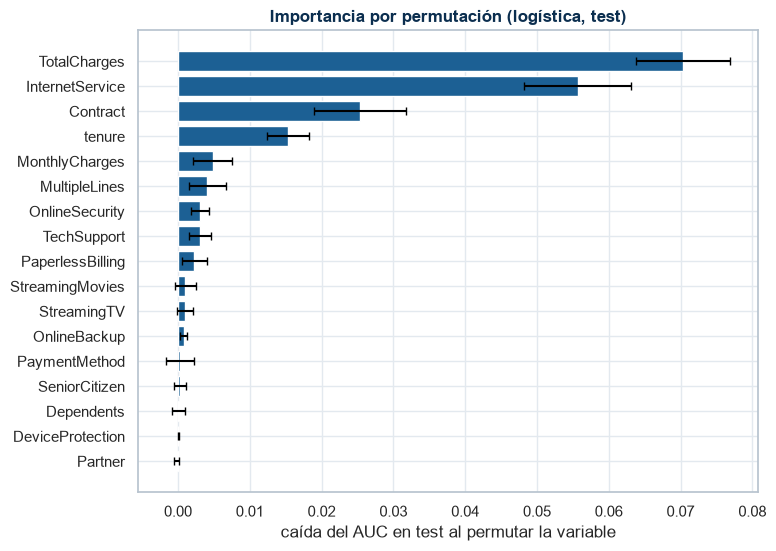

,caída de AUC,desvío
TotalCharges,0.0704,0.0065
InternetService,0.0556,0.0074
Contract,0.0253,0.0065
tenure,0.0153,0.0029
MonthlyCharges,0.0048,0.0027
MultipleLines,0.0041,0.0025


In [54]:
cols_usadas = [c for c in COLS_X if c not in EXCLUIR]       # las 17 variables que usa el modelo
imp = permutation_importance(mejor_logistica, X_test[cols_usadas], y_test, scoring='roc_auc',   # permutación por variable original
                             n_repeats=10, random_state=SEED, n_jobs=-1)   # 10 permutaciones por variable
importancia = pd.DataFrame({'caída de AUC': imp.importances_mean, 'desvío': imp.importances_std},   # media y desvío de la caída
                           index=cols_usadas).sort_values('caída de AUC')   # de menor a mayor

fig, ax = plt.subplots(figsize=(8, 6))                      # figura
ax.barh(importancia.index, importancia['caída de AUC'], xerr=importancia['desvío'], color=AZUL_UTN, capsize=3)   # barras
ax.set_xlabel('caída del AUC en test al permutar la variable')   # eje x
ax.set_title('Importancia por permutación (logística, test)')   # título
guardar_figura('importancia_permutacion')                   # guardo el PNG
plt.show()                                                  # muestro la figura
importancia.sort_values('caída de AUC', ascending=False).head(6)   # las seis más importantes

El modelo depende sobre todo de `TotalCharges`, el tipo de internet, el contrato y `tenure`; las demográficas casi no importan, como en el EDA. Que `TotalCharges` quede primera es coherente con la sección 5: con `log1p` resume antigüedad y gasto en la escala que mejor sigue la caída del riesgo. El medio de pago tiene un odds ratio de 1,4 y una importancia casi nula, y las dos cosas son compatibles. El odds ratio mide el efecto con todo lo demás fijo, mientras que la permutación mide cuánto empeora el orden si se pierde la variable. Gran parte de la información del medio de pago ya la llevan el contrato y la antigüedad. Con variables correlacionadas la importancia se reparte entre ellas, así que `tenure` y `TotalCharges` pueden quedar subestimadas. Hay también un efecto en sentido contrario. Permutar `tenure` o `TotalCharges` por separado rompe la relación `TotalCharges` ≈ `tenure` × `MonthlyCharges` y crea clientes imposibles, como uno de 2 meses con 5.000 de facturación acumulada. El modelo nunca vio combinaciones así, y la caída del AUC puede inflarse. Por eso leemos `TotalCharges` y `tenure` juntas, como un solo bloque de antigüedad, y no ordenamos con precisión entre ellas.

> **Decisión ML14:** interpretar el modelo con odds ratios dentro de cada variable, perfiles de cliente coherentes para las numéricas e importancia por permutación por variable original en test.
>
> **Justificación:** los odds ratios son la lectura natural de una logística y compararlos dentro de cada variable evita leer un coeficiente sin categoría de referencia (James et al., 2023, secs. 3.3.1 y 4.3.3). Los perfiles evitan interpretar por separado tres numéricas colineales. La permutación se aplica a cualquier modelo, se calcula sobre datos no vistos y agrupa las dummies de cada variable (Breiman, 2001; Pedregosa et al., 2011). Permutar por separado variables ligadas puede inflar la caída, así que agrupamos `TotalCharges` con la antigüedad. Los tres caminos, junto con el EDA, señalan las mismas variables principales: contrato, tipo de internet y antigüedad (`tenure` y `TotalCharges`).

## 10.5 Traducción a clientes y facturación

Por último, traducimos el resultado de test a clientes y facturación. Con el umbral de 0,134 contamos a cuántos clientes habría que contactar, cuántas bajas se alcanzan y qué parte de la facturación mensual de los que se van cubre la campaña. Usamos el cargo mensual de cada cliente e ignoramos los pocos que no tienen el dato. Agregamos los costos con el modelo y ofreciendo a todos.

In [55]:
cargo = test['MonthlyCharges'].to_numpy()                   # cargo mensual de cada cliente de test (puede tener NaN)
se_va, ofrece = y_test == 1, p_final >= UMBRAL_TEORICO      # quién se va y a quién le ofrecemos
riesgo = np.nansum(cargo[se_va])                            # facturación mensual de los que se van
cubierto = np.nansum(cargo[se_va & ofrece])                 # la parte de esa facturación a la que llega la campaña
negocio = pd.Series({                                       # tabla de negocio
    'clientes en test': len(y_test),                        # tamaño
    'clientes que se van': int(se_va.sum()),                # bajas
    'facturación mensual en riesgo (% del total)': riesgo / np.nansum(cargo) * 100,   # como en el EDA
    'clientes a contactar': int(ofrece.sum()),              # ofertas
    'clientes a contactar (% del total)': ofrece.mean() * 100,   # en porcentaje
    'bajas alcanzadas': int((se_va & ofrece).sum()),        # verdaderos positivos
    'facturación en riesgo cubierta (%)': cubierto / riesgo * 100,   # cuánto del ingreso en riesgo alcanzamos
    'costo con el modelo': costo_total(y_test, p_final, UMBRAL_TEORICO),   # matriz de la decisión 18
    'costo ofreciendo a todos': costo_total(y_test, p_final, 0.0),   # la mejor estrategia sin modelo
}, name='test')                                             # tabla de negocio
print(negocio.round(1).to_string())                         # muestro la tabla

clientes en test                                1409.0000
clientes que se van                              374.0000
facturación mensual en riesgo (% del total)       30.2000
clientes a contactar                             807.0000
clientes a contactar (% del total)                57.3000
bajas alcanzadas                                 343.0000
facturación en riesgo cubierta (%)                92.4000
costo con el modelo                           124647.0000
costo ofreciendo a todos                      169080.0000


En test, los 374 clientes que se van representan el 30,2% de la facturación mensual, más que su peso en cantidad, porque pagan más que el promedio. Con el umbral por costos, el modelo propone contactar a 807 clientes (57,3% de la cartera), alcanza a 343 de las bajas y cubre el 92,4% de la facturación en riesgo. Con los supuestos de la decisión 18 cuesta 124.647 contra 169.080 de ofrecer a todos, la mejor estrategia sin modelo.

Para priorizar el contacto, describimos al 10% de clientes de test con mayor probabilidad: qué parte tiene contrato mes a mes, fibra y cheque electrónico (entre los que tienen el dato), su antigüedad mediana y su tasa real de bajas. Calculamos también qué parte de todas las bajas concentra el 30% de mayor riesgo.

In [56]:
decil_alto = p_final >= np.quantile(p_final, 0.9)           # el 10% de mayor riesgo
perfil_decil = pd.Series({                                  # perfil del 10% más riesgoso
    'contrato mes a mes (%)': (test.loc[decil_alto, 'Contract'].dropna() == 'Month-to-month').mean() * 100,   # entre los que tienen el dato
    'fibra óptica (%)': (test.loc[decil_alto, 'InternetService'].dropna() == 'Fiber optic').mean() * 100,     # ídem
    'cheque electrónico (%)': (test.loc[decil_alto, 'PaymentMethod'].dropna() == 'Electronic check').mean() * 100,   # ídem
    'antigüedad mediana (meses)': test.loc[decil_alto, 'tenure'].median(),   # antigüedad
    'tasa real de churn (%)': y_test[decil_alto].mean() * 100,   # cuántos se van de verdad
}, name='10% de mayor riesgo')                              # perfil del decil
print('\n' + perfil_decil.round(1).to_string())             # muestro el perfil
decil_test = pd.qcut(p_final, 10, labels=False)             # decil de riesgo de cada cliente de test (9 = el más alto)
top30 = decil_test >= 7                                     # el 30% de mayor riesgo
print(f'\n30% de mayor riesgo: tasa de churn {y_test[top30].mean():.3f} | '   # tasa del 30% más riesgoso
      f'parte de las bajas que concentra {y_test[top30].sum() / y_test.sum():.3f}')   # concentración de las bajas


contrato mes a mes (%)       100.0000
fibra óptica (%)              91.3000
cheque electrónico (%)        78.9000
antigüedad mediana (meses)     3.0000
tasa real de churn (%)        74.5000

30% de mayor riesgo: tasa de churn 0.591 | parte de las bajas que concentra 0.668


El 10% de mayor riesgo está formado por clientes con contrato mes a mes (el 100% de los que tienen el dato), con fibra en un 91,3% y cheque electrónico en un 78,9%. Su antigüedad mediana es de 3 meses y se va el 74,5%. El 30% de mayor riesgo tiene una tasa de bajas de 59,1% y concentra el 66,8% de todas las bajas de test. Las palancas que sugieren el EDA y los odds ratios (contratos más largos, seguridad y soporte, débito automático) quedan como hipótesis para un experimento. Si la oferta resultara menos efectiva de lo supuesto, la tabla de sensibilidad de la sección 7 indica el nuevo umbral.

# 11. Conclusiones, limitaciones y registro de decisiones

## Conclusiones

1. Las decisiones del EDA rinden más que la búsqueda de modelos. Imputar con "Desconocido", aplicar `log1p(TotalCharges)`, recodificar y quitar dos variables sube el AUC de la logística de 0,839 a 0,846. Es más de cuatro veces la ventaja del ensamble en validación, que en test no se repite ni en AUC ni en costo (los dos intervalos incluyen el cero).
2. La logística alcanza. Empata con Random Forest, el boosting y la red neuronal, y un boosting sin interacciones rinde lo mismo que uno con ellas: el churn en esta cartera es casi aditivo en log-odds. A cambio, obtenemos un modelo interpretable con odds ratios y con probabilidades calibradas.
3. El umbral pesa más que el modelo. Con 0,5, la logística cuesta más que ofrecer a todos; con el umbral de costos, 0,134, ahorra un 26,3% frente a esa estrategia en test (IC 95%: 20,5% a 32,1%), y sigue ahorrando en los doce escenarios de sensibilidad.
4. El PCA no mejora la predicción y aporta comprensión. Con 20 componentes pierde unas milésimas de AUC en validación y en test, con un costo casi igual; con Random Forest sobreajusta más y tarda más. Su segunda componente reproduce el perfil de riesgo del EDA.

## Limitaciones

| Limitación | Qué implica |
|---|---|
| Datos de un solo momento | El modelo predice quién figura como baja, no cuándo se va un cliente activo; eso requeriría modelos de supervivencia (James et al., 2023, cap. 11). |
| Costos supuestos | La pérdida de 897 es facturación de un año, no margen, y la efectividad de la oferta es desconocida. La sensibilidad cubre un rango, pero un dato de la empresa la reemplazaría. |
| Faltantes | Suponemos MCAR (decisión 6 del EDA), que no se puede verificar por completo, y que en producción los faltantes aparecen igual. |
| `tenure` con techo en 72 | El valor 72 significa "72 meses o más". |
| Un solo test | El bootstrap cubre la variación de muestreo, no cambios de mercado o de época. |
| Grillas y preprocesamiento | Varias búsquedas eligieron un valor en el borde de su grilla, y el preprocesamiento se eligió con la logística. Los modelos flexibles podrían rendir algo más, aunque todos los candidatos quedan en un rango estrecho de AUC. |
| Asociación y no causa | Ni los odds ratios ni la importancia dicen qué pasaría al intervenir; para eso hace falta un experimento. |

Como próximos pasos, proponemos obtener el margen por cliente y la tasa de aceptación de ofertas anteriores para reemplazar los supuestos de costo. También conviene priorizar por pérdida esperada (probabilidad por cargo del cliente), medir las palancas de retención con un experimento y monitorear la calibración en producción.

## Registro de decisiones

| # | Decisión | Evidencia | Referencia |
|---|---|---|---|
| ML1 | Partir de `telco_manipulado.csv` y apartar el test | Partición del EDA verificada (5.634 y 1.409) | Géron (2022), cap. 2 |
| ML2 | CV estratificada de 5 folds común, ROC-AUC, reglas de adopción fijadas de antemano, matriz de costos | Comparación pareada; AUC independiente del umbral | James et al. (2023), secs. 5.1 y 6.1.3; Nadeau y Bengio (2003) |
| ML3 | Líneas de base: Dummy y logística ingenua | AUC 0,500 y 0,839 | James et al. (2023), sec. 4.4.2 |
| ML4 | "Desconocido" en las categóricas | +0,0025, gana en los 5 folds | Decisión 8 del EDA; Géron (2022), cap. 2 |
| ML5 | `log1p(TotalCharges)` | +0,0045, gana en los 5 folds | Decisión 10 del EDA; James et al. (2023), sec. 3.3.2 |
| ML6 | Recodificar "No internet service" | Mismo AUC con 10 columnas menos | Decisión 11 del EDA |
| ML7 | Sin `gender` ni `PhoneService` | Empate con 42 columnas en lugar de 48 | Decisión 17 del EDA; James et al. (2023), sec. 6.1 |
| ML8 | Mantener `TotalCharges`; sin `n_adicionales`, tramos, `KNNImputer` ni `class_weight` | Ninguna variante mejora; quitar `TotalCharges` empeora | Decisiones 8, 12, 13 y 15 del EDA |
| ML9 | Modelo final: logística; ensamble como contraste | Dentro de 1 EE del mejor; la más simple y la de menor brecha | James et al. (2023), sec. 6.1.3 |
| ML10 | Umbral teórico 0,134 con sensibilidad | Calibrada; en la zona plana de la curva de costo | Murphy (2022), sec. 5.1.2.2 |
| ML11 | PCA con dummies en 0/1 | Estandarizar todo pierde 0,022 (2 comp.) y 0,011 (10 comp.) | James et al. (2023), sec. 12.2.4 |
| ML12 | Componentes y `C` por CV con regla de 1 EE | 20 componentes; Random Forest con PCA sobreajusta más | James et al. (2023), secs. 6.3.1 y 12.2.4 |
| ML13 | Test una sola vez, tres modelos fijados, bootstrap | El ensamble empata; el PCA pierde 0,0056; ahorro de 26,3% | James et al. (2023), sec. 5.2; Efron y Tibshirani (1993) |
| ML14 | Odds ratios con IC bootstrap, perfiles e importancia por permutación | Contrato, internet y antigüedad por tres caminos | James et al. (2023), secs. 3.3.3 y 4.3.3; Breiman (2001) |

# 12. Referencias

**Bibliografía principal**

1. James, G., Witten, D., Hastie, T., Tibshirani, R. y Taylor, J. (2023). *An Introduction to Statistical Learning with Applications in Python*. Springer.
2. Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3.ª ed.). O'Reilly.
3. VanderPlas, J. (2016). *Python Data Science Handbook*. O'Reilly.
4. Murphy, K. P. (2022). *Probabilistic Machine Learning: An Introduction*. MIT Press.

**Papers y herramientas complementarias**

5. Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5-32.
6. Breiman, L., Friedman, J., Olshen, R. y Stone, C. (1984). *Classification and Regression Trees*. Wadsworth.
7. Brier, G. W. (1950). Verification of forecasts expressed in terms of probability. *Monthly Weather Review*, 78(1), 1-3.
8. Cover, T. y Hart, P. (1967). Nearest neighbor pattern classification. *IEEE Transactions on Information Theory*, 13(1), 21-27.
9. Efron, B. y Tibshirani, R. (1993). *An Introduction to the Bootstrap*. Chapman & Hall.
10. Friedman, J. (2001). Greedy function approximation: a gradient boosting machine. *The Annals of Statistics*, 29(5), 1189-1232.
11. Hanley, J. y McNeil, B. (1982). The meaning and use of the area under a receiver operating characteristic (ROC) curve. *Radiology*, 143(1), 29-36.
12. Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q. y Liu, T.-Y. (2017). LightGBM: a highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems*, 30.
13. Nadeau, C. y Bengio, Y. (2003). Inference for the generalization error. *Machine Learning*, 52(3), 239-281.
14. Niculescu-Mizil, A. y Caruana, R. (2005). Predicting good probabilities with supervised learning. *Proceedings of the 22nd International Conference on Machine Learning*, 625-632.
15. Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825-2830.
16. Verbraken, T., Verbeke, W. y Baesens, B. (2013). A novel profit maximizing metric for measuring classification performance of customer churn prediction models. *IEEE Transactions on Knowledge and Data Engineering*, 25(5), 961-973.